In [1]:
cd /content/drive/MyDrive/SOK

/content/drive/MyDrive/SOK


# Grad-cam

1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
Image: /content/drive/MyDrive/SOK/skin-cancer/test/benign/1253.jpg | Predicted: Benign | Confidence: 0.99
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 290ms/step
0.010594588
Image: /content/drive/MyDrive/SOK/skin-cancer/test/benign/1253.jpg | Predicted: Benign | Confidence: 0.99


/usr/local/lib/python3.11/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: [['input_layer']]
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)


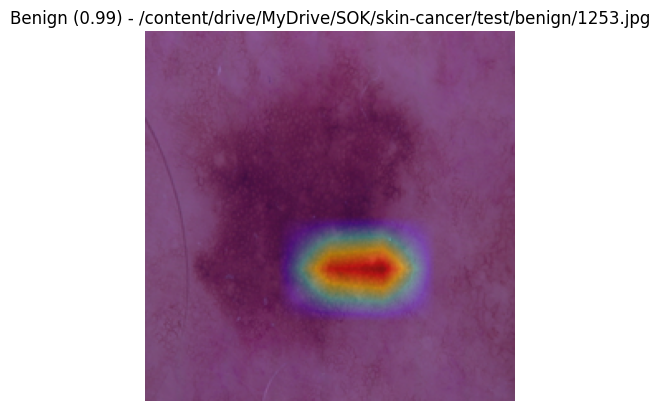

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 183ms/step
Image: /content/drive/MyDrive/SOK/skin-cancer/test/malignant/593.jpg | Predicted: Malignant | Confidence: 0.99
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 208ms/step
0.9949866
Image: /content/drive/MyDrive/SOK/skin-cancer/test/malignant/593.jpg | Predicted: Malignant | Confidence: 0.99


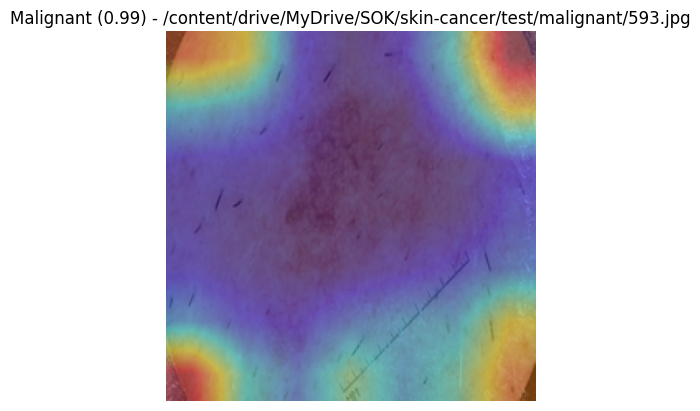

In [ ]:
import os
import numpy as np
import tensorflow as tf
import cv2
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing import image
import matplotlib.pyplot as plt

# Paths
model_path = "/content/drive/MyDrive/SOK/model/resnet50_sk_detection_finetuned.h5"
test_dirs = {
    "benign": "/content/drive/MyDrive/SOK/skin-cancer/train/benign",
    "malignant": "/content/drive/MyDrive/SOK/skin-cancer/train/malignant"
}


model = load_model(model_path)
last_conv_layer_name = "conv5_block3_out"

def make_gradcam_heatmap(img_array, model, last_conv_layer_name):
    grad_model = tf.keras.models.Model(
        [model.inputs], [model.get_layer(last_conv_layer_name).output, model.output]
    )
    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_array)
        pred_index = tf.argmax(predictions[0])
        class_channel = predictions[:, pred_index]

    grads = tape.gradient(class_channel, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_outputs = conv_outputs[0]

    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)

    heatmap = tf.maximum(heatmap, 0) / tf.math.reduce_max(heatmap)
    return heatmap.numpy()

def print_output_label(img_path):
    img = image.load_img(img_path, target_size=(224, 224))
    img_array = image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)
    img_array = tf.keras.applications.resnet50.preprocess_input(img_array)
    prediction = model.predict(img_array)
    prob = prediction[0][0]
    predicted_class = int(prob > 0.5)
    label = "Malignant" if predicted_class == 1 else "Benign"
    confidence = prob if predicted_class == 1 else 1 - prob
    print(f"Image: {img_path} | Predicted: {label} | Confidence: {confidence:.2f}")


def process_directory(class_name):
    input_dir = test_dirs[class_name]

    # for fname in os.listdir(input_dir):
    #     if fname.lower().endswith(('.png', '.jpg', '.jpeg')):
    if class_name == "benign":
        fname = '/content/drive/MyDrive/SOK/skin-cancer/test/benign/1253.jpg'
    else:
        fname = '/content/drive/MyDrive/SOK/skin-cancer/test/malignant/593.jpg'
    img_path = os.path.join(input_dir, fname)
    print_output_label(img_path)
    img = image.load_img(img_path, target_size=(224, 224))
    img_array = image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)
    img_array = tf.keras.applications.resnet50.preprocess_input(img_array)


    prediction = model.predict(img_array)
    prob = prediction[0][0]
    print(prob)
    predicted_class = int(prob > 0.5)
    label = "Malignant" if predicted_class == 1 else "Benign"
    confidence = prob if predicted_class == 1 else 1 - prob
    print(f"Image: {fname} | Predicted: {label} | Confidence: {confidence:.2f}")

    heatmap = make_gradcam_heatmap(img_array, model, last_conv_layer_name)

    original_img = cv2.imread(img_path)
    original_img = cv2.resize(original_img, (224, 224))
    heatmap_resized = cv2.resize(heatmap, (224, 224))
    heatmap_colored = cv2.applyColorMap(np.uint8(255 * heatmap_resized), cv2.COLORMAP_JET)
    superimposed_img = cv2.addWeighted(original_img, 0.6, heatmap_colored, 0.4, 0)


    plt.imshow(cv2.cvtColor(superimposed_img, cv2.COLOR_BGR2RGB))
    plt.axis('off')
    plt.title(f"{label} ({confidence:.2f}) - {fname}")
    plt.show()



process_directory("benign")
process_directory("malignant")

# LIME

In [ ]:
!pip install lime

In [ ]:
import os
import glob
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing import image
from lime import lime_image
from skimage.segmentation import mark_boundaries

MODEL_PATH = '/content/drive/MyDrive/SOK/model/resnet50_sk_detection_finetuned.h5'
BENIGN_DIR = '/content/drive/MyDrive/SOK/test/benign_test'
MALIGNANT_DIR = '/content/drive/MyDrive/SOK/test/malignant_test'

model = load_model(MODEL_PATH)

def load_and_preprocess_image(img_path, target_size=(224, 224)):
    """Loads image and returns it as a numpy array (unpreprocessed) for LIME."""
    img = image.load_img(img_path, target_size=target_size)
    x = image.img_to_array(img)
    return x

def model_predict(images):
    images_preprocessed = np.array([tf.keras.applications.resnet50.preprocess_input(img) for img in images])
    preds = model.predict(images_preprocessed)
    return preds

def get_all_images_with_labels():
    X, paths, labels = [], [], []
    for label, folder in [("malignant", MALIGNANT_DIR), ("benign", BENIGN_DIR) ]:
        for path in glob.glob(os.path.join(folder, "*.*")):
            paths.append(path)
            labels.append(label)
    return np.array(X), paths, labels


X_test, all_paths, all_labels = get_all_images_with_labels()
print(f"Loaded {len(X_test)} images for LIME")

explainer = lime_image.LimeImageExplainer()

def print_output_label(img_path):
    img = image.load_img(img_path, target_size=(224, 224))
    img_array = image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)
    img_array = tf.keras.applications.resnet50.preprocess_input(img_array)
    prediction = model.predict(img_array)
    prob = prediction[0][0]
    predicted_class = int(prob > 0.5)
    label = "Malignant" if predicted_class == 1 else "Benign"
    confidence = prob if predicted_class == 1 else 1 - prob
    print(f"Image: {img_path} | Predicted: {label} | Confidence: {confidence:.2f}")


for i, (img_path, label) in enumerate(zip(all_paths, all_labels)):
    print_output_label(img_path)
    img = load_and_preprocess_image(img_path)  # shape: (224, 224, 3)
    explanation = explainer.explain_instance(
        img.astype('double'),
        model_predict,
        top_labels=1,
        hide_color=0,
        num_samples=500
    )

    top_pred_class = explanation.top_labels[0]
    temp, mask = explanation.get_image_and_mask(
        top_pred_class,
        positive_only=True,
        num_features=5,
        hide_rest=False
    )
    lime_img = mark_boundaries(temp / 255.0, mask)

    fig, ax = plt.subplots(1, 2, figsize=(10, 4))
    ax[0].imshow(img.astype('uint8'))
    ax[0].set_title("Original")
    ax[0].axis('off')

    ax[1].imshow(lime_img)
    ax[1].set_title("LIME Explanation")
    ax[1].axis('off')

    fig.suptitle(f"{label.capitalize()} - {os.path.basename(img_path)}", fontsize=12)
    plt.tight_layout()
    plt.show()


# Saliency Map

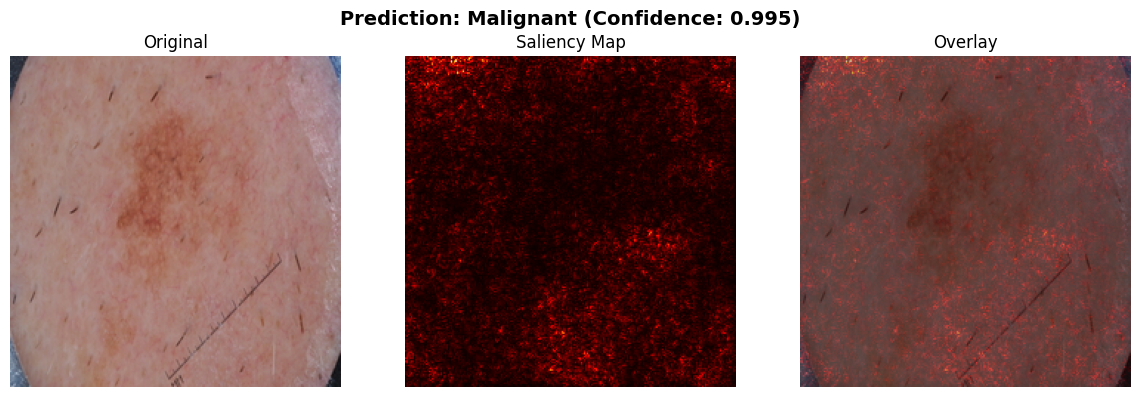

Model prediction: Malignant with 99.5% confidence


In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing import image
from tensorflow.keras.applications.imagenet_utils import preprocess_input

def compute_saliency(model_path, img_path):
    # Load model and image
    model = load_model(model_path)
    img = image.load_img(img_path, target_size=(224, 224))
    img_array = np.expand_dims(image.img_to_array(img), axis=0)
    img_preprocessed = preprocess_input(img_array.copy())

    # Compute gradients
    img_tensor = tf.convert_to_tensor(img_preprocessed, dtype=tf.float32)
    with tf.GradientTape() as tape:
        tape.watch(img_tensor)
        predictions = model(img_tensor)
        target_score = predictions[0][0]  # Single output value

    gradients = tape.gradient(target_score, img_tensor).numpy()[0]

    # Create saliency map
    saliency = np.max(np.abs(gradients), axis=-1)
    saliency = (saliency - saliency.min()) / (saliency.max() - saliency.min())

    # Get prediction info (single output binary classification)
    pred_prob = predictions[0][0].numpy()  # Single probability value
    pred_class = 1 if pred_prob > 0.5 else 0  # 1 for malignant, 0 for benign
    confidence = pred_prob if pred_prob > 0.5 else (1 - pred_prob)
    class_names = ['Benign', 'Malignant']

    # Visualize
    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(12, 4))

    ax1.imshow(img)
    ax1.set_title('Original')
    ax1.axis('off')

    ax2.imshow(saliency, cmap='hot')
    ax2.set_title('Saliency Map')
    ax2.axis('off')

    ax3.imshow(img)
    ax3.imshow(saliency, cmap='hot', alpha=0.5)
    ax3.set_title('Overlay')
    ax3.axis('off')

    plt.suptitle(f'Prediction: {class_names[pred_class]} (Confidence: {confidence:.3f})',
                 fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

    print(f"Model prediction: {class_names[pred_class]} with {confidence:.1%} confidence")

    return saliency

# Usage
model_path = '/content/drive/MyDrive/SOK/model/resnet50_sk_detection_finetuned.h5'
img_path = '/content/drive/MyDrive/SOK/skin-cancer/test/malignant/593.jpg'


# fname = '/content/drive/MyDrive/SOK/skin-cancer/test/benign/1253.jpg'

# fname = '/content/drive/MyDrive/SOK/skin-cancer/test/malignant/593.jpg'

saliency_map = compute_saliency(model_path, img_path)

# Shap Global

In [ ]:
import os
import glob
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing import image
import shap
import io
from PIL import Image


MODEL_PATH = '/content/drive/MyDrive/SOK/model/resnet50_sk_detection_finetuned.h5'
NORMAL_DIR = '/content/drive/MyDrive/SOK/test/benign_test'
PNEUMONIA_DIR = '/content/drive/MyDrive/SOK/test/malignant_test'


model = load_model(MODEL_PATH)


def load_and_preprocess_image(img_path, target_size=(224, 224)):
    img = image.load_img(img_path, target_size=target_size)
    x = image.img_to_array(img)
    x = np.expand_dims(x, axis=0)
    x = tf.keras.applications.resnet50.preprocess_input(x)
    return x


def build_background_data(directory, num_images=5):
    image_paths = glob.glob(os.path.join(directory, '*.*'))[:num_images]
    background_list = []
    for path in image_paths:
        x = load_and_preprocess_image(path)
        background_list.append(x[0])
    if len(background_list) == 0:
        return np.zeros((1, 224, 224, 3))
    return np.stack(background_list, axis=0)

background_data = build_background_data(NORMAL_DIR, num_images=5)


def get_all_images_with_labels():
    X, paths, labels = [], [], []
    for label, folder in [("NORMAL", NORMAL_DIR), ("PNEUMONIA", PNEUMONIA_DIR)]:
        for path in glob.glob(os.path.join(folder, "*.*")):
            x = load_and_preprocess_image(path)
            X.append(x[0])
            paths.append(path)
            labels.append(label)
    return np.stack(X, axis=0), paths, labels

X_test, all_paths, all_labels = get_all_images_with_labels()
print(f"Loaded {len(X_test)} images for SHAP")
class_names = ["Normal", "Pneumonia"]
masker = shap.maskers.Image("inpaint_telea", X_test[0].shape)
explainer = shap.Explainer(model, masker, output_names=class_names)

batch_size = 2
for start in range(0, len(X_test[0:10]), batch_size):
    end = min(start + batch_size, len(X_test))

    shap_values = explainer(X_test[start:end], max_evals=200, batch_size=50, outputs=shap.Explanation.argsort.flip[:1])
    shap_maps = shap_values[0] if isinstance(shap_values, list) else shap_values

    batch_paths = all_paths[start:end]
    batch_labels = all_labels[start:end]
    for i, (img_path, label) in enumerate(zip(batch_paths, batch_labels)):
        original_img_pil = image.load_img(img_path, target_size=(224,224))
        shap_map = shap_maps[i]

        original_np = np.array(original_img_pil).astype(np.float32) / 255.0

        temp_buffer = io.BytesIO()
        plt.figure(figsize=(5, 5))
        shap.image_plot(shap_map, show=False)
        plt.savefig(temp_buffer, format='png')
        plt.close()

        temp_buffer.seek(0)
        shap_img = Image.open(temp_buffer)
        shap_img_np = np.array(shap_img)

        fig, ax = plt.subplots(1, 2, figsize=(10, 4))
        ax[0].imshow(original_img_pil)
        ax[0].set_title("Original")
        ax[0].axis('off')

        ax[1].imshow(shap_img_np)
        ax[1].set_title("SHAP Explanation")
        ax[1].axis('off')

        fig.suptitle(f"{label.capitalize()} - {os.path.basename(img_path)}", fontsize=12)
        plt.tight_layout()

        plt.show()


In [ ]:
import os
import glob
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import load_model, Model
from tensorflow.keras.preprocessing import image
from tensorflow.keras.applications.resnet50 import preprocess_input
import matplotlib.pyplot as plt
import cv2
from matplotlib.colors import LinearSegmentedColormap

# Paths
MODEL_PATH = '/content/drive/MyDrive/SOK/resnet50_sk_detection_finetuned.h5'
MALIGNANT_DIR = '/content/drive/MyDrive/SOK/skin-cancer/train/malignant'

# Load model
model = load_model(MODEL_PATH)

# Create Grad-CAM model (we need the last convolutional layer)
def get_gradcam_model(model):
    """
    Create a model that outputs both the final predictions and the feature maps
    from the last convolutional layer
    """
    # Find the last convolutional layer
    last_conv_layer = None
    for layer in reversed(model.layers):
        if isinstance(layer, (tf.keras.layers.Conv2D, tf.keras.layers.DepthwiseConv2D)):
            last_conv_layer = layer
            break

    if last_conv_layer is None:
        # If no conv layer found, try looking for common ResNet layer names
        for layer_name in ['conv5_block3_out', 'conv4_block6_out', 'activation_49']:
            try:
                last_conv_layer = model.get_layer(layer_name)
                break
            except:
                continue

    if last_conv_layer is None:
        raise ValueError("Could not find a convolutional layer in the model")

    print(f"Using layer: {last_conv_layer.name} for Grad-CAM")

    # Create the grad-cam model
    gradcam_model = Model(
        inputs=model.inputs,
        outputs=[last_conv_layer.output, model.output]
    )

    return gradcam_model, last_conv_layer.name

# Load images with proper color handling
def load_malignant_images():
    X = []
    X_original = []
    image_paths = []

    for path in glob.glob(os.path.join(MALIGNANT_DIR, "*.*"))[:30]:
        img = image.load_img(path, target_size=(224, 224))
        img_array = image.img_to_array(img)

        # Original image array
        X_original.append(img_array.astype(np.uint8))

        # Preprocessed version for model
        x = preprocess_input(np.expand_dims(img_array, axis=0))
        X.append(x[0])

        image_paths.append(path)

    return np.array(X), np.array(X_original), image_paths

def generate_gradcam_heatmap(gradcam_model, img_array, class_index=0, alpha=0.4):
    """
    Generate Grad-CAM heatmap for a given image
    """
    # Expand dimensions to match model input
    img_tensor = tf.expand_dims(img_array, axis=0)

    # Record operations for automatic differentiation
    with tf.GradientTape() as tape:
        # Get the feature maps and predictions
        conv_outputs, predictions = gradcam_model(img_tensor)

        # Get the loss for the predicted class (or specified class)
        if class_index is None:
            class_index = tf.argmax(predictions[0])
        class_channel = predictions[:, class_index]

    # Calculate gradients of the predicted class with respect to feature maps
    grads = tape.gradient(class_channel, conv_outputs)

    # Calculate the mean gradient for each feature map
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    # Weight the feature maps by the gradients
    conv_outputs = conv_outputs[0]
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)

    # Normalize the heatmap
    heatmap = tf.maximum(heatmap, 0) / tf.math.reduce_max(heatmap)

    return heatmap.numpy()

def superimpose_heatmap_on_image(img, heatmap, alpha=0.4, colormap=cv2.COLORMAP_JET):
    """
    Superimpose the heatmap on the original image
    """
    # Resize heatmap to match image dimensions
    heatmap_resized = cv2.resize(heatmap, (img.shape[1], img.shape[0]))

    # Convert heatmap to RGB
    heatmap_colored = cv2.applyColorMap(np.uint8(255 * heatmap_resized), colormap)
    heatmap_colored = cv2.cvtColor(heatmap_colored, cv2.COLOR_BGR2RGB)

    # Ensure image is in the right format
    if img.dtype != np.uint8:
        img = np.uint8(img)

    # Superimpose the heatmap on the original image
    superimposed_img = heatmap_colored * alpha + img * (1 - alpha)
    superimposed_img = np.uint8(superimposed_img)

    return superimposed_img, heatmap_resized

# Load data
X_malignant, X_original, image_paths = load_malignant_images()
print(f"Loaded {len(X_malignant)} malignant images")

# Create Grad-CAM model
gradcam_model, conv_layer_name = get_gradcam_model(model)

# Generate Grad-CAM explanations for all 30 images
print("Generating Grad-CAM explanations for 30 images...")
gradcam_heatmaps = []
predictions_list = []

for i in range(len(X_malignant)):
    # Get prediction
    pred = model.predict(np.expand_dims(X_malignant[i], axis=0), verbose=0)[0]
    predictions_list.append(pred)

    # Generate Grad-CAM heatmap (class_index=0 for malignant prediction)
    heatmap = generate_gradcam_heatmap(gradcam_model, X_malignant[i], class_index=0)
    gradcam_heatmaps.append(heatmap)

# Convert to numpy arrays
gradcam_heatmaps = np.array(gradcam_heatmaps)
predictions_array = np.array(predictions_list).flatten()

print("\nCreating global Grad-CAM explanation from 30 images...")

# Create global explanation by averaging heatmaps
# First, resize all heatmaps to a common size (224, 224)
resized_heatmaps = []
for heatmap in gradcam_heatmaps:
    resized_heatmap = cv2.resize(heatmap, (224, 224))
    resized_heatmaps.append(resized_heatmap)

global_heatmap = np.mean(resized_heatmaps, axis=0)

# Visualize global result
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
# Average original image
avg_img = np.mean(X_original, axis=0).astype(np.uint8)
plt.imshow(avg_img)
plt.title('Average Malignant Image\n(30 samples)', fontsize=12, fontweight='bold')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(global_heatmap, cmap='jet')
plt.title('Global Grad-CAM Heatmap\nfor Malignant Class', fontsize=12, fontweight='bold')
plt.colorbar(shrink=0.8)
plt.axis('off')

plt.subplot(1, 3, 3)
# Overlay on average image
superimposed_global, _ = superimpose_heatmap_on_image(avg_img, global_heatmap, alpha=0.5)
plt.imshow(superimposed_global)
plt.title('Global Heatmap Overlay\n(on Average Image)', fontsize=12, fontweight='bold')
plt.axis('off')

plt.tight_layout()
plt.show()

# Calculate and display prediction statistics
print(f"\nGrad-CAM analysis completed for {len(X_malignant)} malignant images!")
print("Global explanation shows regions that consistently contribute to malignant prediction")

print("\nPrediction Statistics:")
print(f"Average malignant probability: {np.mean(predictions_array):.3f} ± {np.std(predictions_array):.3f}")
print(f"Min malignant probability: {np.min(predictions_array):.3f}")
print(f"Max malignant probability: {np.max(predictions_array):.3f}")
print(f"Images with >0.5 malignant probability: {np.sum(predictions_array > 0.5)}/30")

# Show distribution of predictions
plt.figure(figsize=(10, 6))
plt.hist(predictions_array, bins=15, alpha=0.7, edgecolor='black')
plt.axvline(x=0.5, color='red', linestyle='--', label='Decision Threshold')
plt.xlabel('Malignant Probability')
plt.ylabel('Number of Images')
plt.title('Distribution of Malignant Predictions\n(30 Test Images)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# Display sample Grad-CAM explanations
print("\nDisplaying sample Grad-CAM explanations (first 30 images)...")
plt.figure(figsize=(60, 36))

for i in range(min(30, len(X_original))):
    # Original image
    plt.subplot(3, 30, i+1)
    plt.imshow(X_original[i])
    plt.title(f'Original {i+1}\nMal: {predictions_array[i]:.3f}', fontsize=8, fontweight='bold')
    plt.axis('off')

    # Grad-CAM heatmap
    plt.subplot(3, 30, i+31)
    heatmap_resized = cv2.resize(gradcam_heatmaps[i], (224, 224))
    plt.imshow(heatmap_resized, cmap='jet')
    plt.title('Grad-CAM Heatmap', fontsize=8, fontweight='bold')
    plt.axis('off')

    # Superimposed image
    plt.subplot(3, 30, i+61)
    superimposed, _ = superimpose_heatmap_on_image(X_original[i], heatmap_resized, alpha=0.5)
    plt.imshow(superimposed)
    plt.title('Heatmap Overlay', fontsize=8, fontweight='bold')
    plt.axis('off')

plt.tight_layout()
plt.show()

print("\nAnalysis Summary:")
print("- Red/Yellow regions: Areas that strongly contribute to malignant prediction")
print("- Blue/Purple regions: Areas with minimal contribution to the prediction")
print("- The global heatmap shows consistent activation patterns across all 30 images")
print("- Grad-CAM highlights regions the model focuses on when making predictions")

# Additional analysis: Show top activated regions statistics
print("\nHeatmap Statistics:")
for i in range(5):  # Show stats for first 5 images
    heatmap = cv2.resize(gradcam_heatmaps[i], (224, 224))
    max_activation = np.max(heatmap)
    mean_activation = np.mean(heatmap)
    print(f"Image {i+1}: Max activation: {max_activation:.3f}, Mean activation: {mean_activation:.3f}")

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
import os
import glob
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import load_model, Model
from tensorflow.keras.preprocessing import image
from tensorflow.keras.applications.resnet50 import preprocess_input
import matplotlib.pyplot as plt
import cv2
from matplotlib.colors import LinearSegmentedColormap

# Paths
MODEL_PATH = '/content/drive/MyDrive/SOK/resnet50_sk_detection_finetuned.h5'
BENIGN_DIR = '/content/drive/MyDrive/SOK/skin-cancer/train/benign'

# Load model
model = load_model(MODEL_PATH)

# Create Grad-CAM model (we need the last convolutional layer)
def get_gradcam_model(model):
    """
    Create a model that outputs both the final predictions and the feature maps
    from the last convolutional layer
    """
    # Find the last convolutional layer
    last_conv_layer = None
    for layer in reversed(model.layers):
        if isinstance(layer, (tf.keras.layers.Conv2D, tf.keras.layers.DepthwiseConv2D)):
            last_conv_layer = layer
            break

    if last_conv_layer is None:
        # If no conv layer found, try looking for common ResNet layer names
        for layer_name in ['conv5_block3_out', 'conv4_block6_out', 'activation_49']:
            try:
                last_conv_layer = model.get_layer(layer_name)
                break
            except:
                continue

    if last_conv_layer is None:
        raise ValueError("Could not find a convolutional layer in the model")

    print(f"Using layer: {last_conv_layer.name} for Grad-CAM")

    # Create the grad-cam model
    gradcam_model = Model(
        inputs=model.inputs,
        outputs=[last_conv_layer.output, model.output]
    )

    return gradcam_model, last_conv_layer.name

# Load images with proper color handling
def load_benign_images():
    X = []
    X_original = []
    image_paths = []

    for path in glob.glob(os.path.join(BENIGN_DIR, "*.*"))[:30]:
        img = image.load_img(path, target_size=(224, 224))
        img_array = image.img_to_array(img)

        # Original image array
        X_original.append(img_array.astype(np.uint8))

        # Preprocessed version for model
        x = preprocess_input(np.expand_dims(img_array, axis=0))
        X.append(x[0])

        image_paths.append(path)

    return np.array(X), np.array(X_original), image_paths

def generate_gradcam_heatmap(gradcam_model, img_array, for_benign=True, alpha=0.4):
    """
    Generate Grad-CAM heatmap for a given image
    for_benign: True to generate heatmap for benign prediction, False for malignant
    """
    # Expand dimensions to match model input
    img_tensor = tf.expand_dims(img_array, axis=0)

    # Record operations for automatic differentiation
    with tf.GradientTape() as tape:
        # Get the feature maps and predictions
        conv_outputs, predictions = gradcam_model(img_tensor)

        # Handle both single output (sigmoid) and multi-output models
        if predictions.shape[-1] == 1:
            # Single output model (sigmoid) - output is malignant probability
            if for_benign:
                # For benign, we want gradient w.r.t (1 - malignant_prob)
                class_channel = 1.0 - predictions[:, 0]
            else:
                # For malignant, use the output directly
                class_channel = predictions[:, 0]
        else:
            # Multi-output model - assume [malignant_prob, benign_prob]
            if for_benign:
                class_channel = predictions[:, 1]  # benign class
            else:
                class_channel = predictions[:, 0]  # malignant class

    # Calculate gradients of the target class with respect to feature maps
    grads = tape.gradient(class_channel, conv_outputs)

    # Calculate the mean gradient for each feature map
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    # Weight the feature maps by the gradients
    conv_outputs = conv_outputs[0]
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)

    # Normalize the heatmap
    heatmap = tf.maximum(heatmap, 0) / tf.math.reduce_max(heatmap)

    return heatmap.numpy()

def superimpose_heatmap_on_image(img, heatmap, alpha=0.4, colormap=cv2.COLORMAP_JET):
    """
    Superimpose the heatmap on the original image
    """
    # Resize heatmap to match image dimensions
    heatmap_resized = cv2.resize(heatmap, (img.shape[1], img.shape[0]))

    # Convert heatmap to RGB
    heatmap_colored = cv2.applyColorMap(np.uint8(255 * heatmap_resized), colormap)
    heatmap_colored = cv2.cvtColor(heatmap_colored, cv2.COLOR_BGR2RGB)

    # Ensure image is in the right format
    if img.dtype != np.uint8:
        img = np.uint8(img)

    # Superimpose the heatmap on the original image
    superimposed_img = heatmap_colored * alpha + img * (1 - alpha)
    superimposed_img = np.uint8(superimposed_img)

    return superimposed_img, heatmap_resized

# Load data
X_benign, X_original, image_paths = load_benign_images()
print(f"Loaded {len(X_benign)} benign images")

# Create Grad-CAM model
gradcam_model, conv_layer_name = get_gradcam_model(model)

# Generate Grad-CAM explanations for all 30 images
print("Generating Grad-CAM explanations for 30 benign images...")
gradcam_heatmaps = []
predictions_list = []

# First, let's check the model output shape
sample_pred = model.predict(np.expand_dims(X_benign[0], axis=0), verbose=0)
print(f"Model output shape: {sample_pred.shape}")
print(f"Sample prediction: {sample_pred}")

for i in range(len(X_benign)):
    # Get prediction
    pred = model.predict(np.expand_dims(X_benign[i], axis=0), verbose=0)[0]
    predictions_list.append(pred)

    # Generate Grad-CAM heatmap for benign prediction
    heatmap = generate_gradcam_heatmap(gradcam_model, X_benign[i], for_benign=True)
    gradcam_heatmaps.append(heatmap)

# Convert to numpy arrays
gradcam_heatmaps = np.array(gradcam_heatmaps)
predictions_array = np.array(predictions_list).flatten()

# For benign analysis, we want to look at benign probabilities (1 - malignant_prob)
benign_probabilities = 1 - predictions_array

print("\nCreating global Grad-CAM explanation from 30 benign images...")

# Create global explanation by averaging heatmaps
# First, resize all heatmaps to a common size (224, 224)
resized_heatmaps = []
for heatmap in gradcam_heatmaps:
    resized_heatmap = cv2.resize(heatmap, (224, 224))
    resized_heatmaps.append(resized_heatmap)

global_heatmap = np.mean(resized_heatmaps, axis=0)

# Visualize global result
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
# Average original image
avg_img = np.mean(X_original, axis=0).astype(np.uint8)
plt.imshow(avg_img)
plt.title('Average Benign Image\n(30 samples)', fontsize=12, fontweight='bold')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(global_heatmap, cmap='jet')
plt.title('Global Grad-CAM Heatmap\nfor Benign Class', fontsize=12, fontweight='bold')
plt.colorbar(shrink=0.8)
plt.axis('off')

plt.subplot(1, 3, 3)
# Overlay on average image
superimposed_global, _ = superimpose_heatmap_on_image(avg_img, global_heatmap, alpha=0.5)
plt.imshow(superimposed_global)
plt.title('Global Heatmap Overlay\n(on Average Image)', fontsize=12, fontweight='bold')
plt.axis('off')

plt.tight_layout()
plt.show()

# Calculate and display prediction statistics
print(f"\nGrad-CAM analysis completed for {len(X_benign)} benign images!")
print("Global explanation shows regions that consistently contribute to benign prediction")

print("\nPrediction Statistics:")
print(f"Average malignant probability: {np.mean(predictions_array):.3f} ± {np.std(predictions_array):.3f}")
print(f"Average benign probability: {np.mean(benign_probabilities):.3f} ± {np.std(benign_probabilities):.3f}")
print(f"Min malignant probability: {np.min(predictions_array):.3f}")
print(f"Max malignant probability: {np.max(predictions_array):.3f}")
print(f"Images with <0.5 malignant probability (correctly classified as benign): {np.sum(predictions_array < 0.5)}/30")

# Show distribution of predictions
plt.figure(figsize=(10, 6))
plt.hist(benign_probabilities, bins=15, alpha=0.7, edgecolor='black', color='green', label='Benign Probability')
plt.hist(predictions_array, bins=15, alpha=0.5, edgecolor='black', color='red', label='Malignant Probability')
plt.axvline(x=0.5, color='black', linestyle='--', label='Decision Threshold')
plt.xlabel('Probability')
plt.ylabel('Number of Images')
plt.title('Distribution of Predictions for Benign Images\n(30 Test Images)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# Display sample Grad-CAM explanations
print("\nDisplaying sample Grad-CAM explanations for benign images (first 30 images)...")
plt.figure(figsize=(60, 36))

for i in range(min(30, len(X_original))):
    # Original image
    plt.subplot(3, 30, i+1)
    plt.imshow(X_original[i])
    plt.title(f'Original {i+1}\nBenign: {benign_probabilities[i]:.3f}\nMal: {predictions_array[i]:.3f}', fontsize=8, fontweight='bold')
    plt.axis('off')

    # Grad-CAM heatmap
    plt.subplot(3, 30, i+31)
    heatmap_resized = cv2.resize(gradcam_heatmaps[i], (224, 224))
    plt.imshow(heatmap_resized, cmap='jet')
    plt.title('Grad-CAM Heatmap', fontsize=8, fontweight='bold')
    plt.axis('off')

    # Superimposed image
    plt.subplot(3, 30, i+61)
    superimposed, _ = superimpose_heatmap_on_image(X_original[i], heatmap_resized, alpha=0.5)
    plt.imshow(superimposed)
    plt.title('Heatmap Overlay', fontsize=8, fontweight='bold')
    plt.axis('off')

plt.tight_layout()
plt.show()

print("\nAnalysis Summary:")
print("- Red/Yellow regions: Areas that strongly contribute to benign prediction")
print("- Blue/Purple regions: Areas with minimal contribution to the prediction")
print("- The global heatmap shows consistent activation patterns across all 30 benign images")
print("- Grad-CAM highlights regions the model focuses on when predicting benign class")
print("- For benign images, we expect most predictions to be <0.5 (correctly classified)")

# Additional analysis: Show top activated regions statistics
print("\nHeatmap Statistics (Benign Class Activations):")
for i in range(5):  # Show stats for first 5 images
    heatmap = cv2.resize(gradcam_heatmaps[i], (224, 224))
    max_activation = np.max(heatmap)
    mean_activation = np.mean(heatmap)
    print(f"Image {i+1}: Max activation: {max_activation:.3f}, Mean activation: {mean_activation:.3f}, Benign prob: {benign_probabilities[i]:.3f}")

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
import os
import glob
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing import image
from tensorflow.keras.applications.resnet50 import preprocess_input
import shap

MODEL_PATH = '/content/drive/MyDrive/SOK/model/resnet50_sk_detection_finetuned.h5'
BENIGN_DIR = '/content/drive/MyDrive/SOK/test/benign_test'
MALIGNANT_DIR = '/content/drive/MyDrive/SOK/test/malignant_test'

model = load_model(MODEL_PATH)

def load_images():
    X, labels = [], []
    for label, folder in [(0, BENIGN_DIR), (1, MALIGNANT_DIR)]:
        for path in glob.glob(os.path.join(folder, "*.*"))[:5]:
            img = image.load_img(path, target_size=(224, 224))
            x = preprocess_input(np.expand_dims(image.img_to_array(img), axis=0))
            X.append(x[0])
            labels.append(label)
    return np.array(X), labels

X_test, labels = load_images()
print(f"Loaded {len(X_test)} images")


masker = shap.maskers.Image("inpaint_telea", X_test[0].shape)
explainer = shap.Explainer(model, masker, output_names=["Benign", "Malignant"])

shap_values = explainer(X_test[:3], max_evals=100)
shap.image_plot(shap_values, show=True)

In [ ]:
import os
import glob
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing import image
from tensorflow.keras.applications.resnet50 import preprocess_input
import shap

MODEL_PATH = '/content/drive/MyDrive/SOK/model/resnet50_sk_detection_finetuned.h5'
BENIGN_DIR = '/content/drive/MyDrive/SOK/test/benign'

model = load_model(MODEL_PATH)

def load_benign_images():
    X, labels = [], []
    # Load only benign images (label = 0)
    for path in glob.glob(os.path.join(BENIGN_DIR, "*.*"))[:50]:
        img = image.load_img(path, target_size=(224, 224))
        x = preprocess_input(np.expand_dims(image.img_to_array(img), axis=0))
        X.append(x[0])
        labels.append(0)  # All labels are 0 (benign)
    return np.array(X), labels

X_test, labels = load_benign_images()
print(f"Loaded {len(X_test)} benign images")

# Create masker using the first benign image
masker = shap.maskers.Image("inpaint_telea", X_test[0].shape)
explainer = shap.Explainer(model, masker, output_names=["Benign", "Malignant"])

# Generate SHAP values for benign images
shap_values = explainer(X_test[:3], max_evals=100)

# Plot SHAP explanations for benign images
shap.image_plot(shap_values, show=True)

# Optional: Print predictions for the benign images
predictions = model.predict(X_test)
print(f"\nPrediction shape: {predictions.shape}")
print("\nPredictions for benign images:")

for i, pred in enumerate(predictions):
    if len(pred.shape) == 0 or pred.shape[0] == 1:
        # Single output model (sigmoid): pred[0] is probability of malignant
        malignant_prob = pred[0] if len(pred) > 0 else pred
        benign_prob = 1 - malignant_prob
        print(f"Image {i+1}: Benign={benign_prob:.3f}, Malignant={malignant_prob:.3f}")
    else:
        # Two output model: pred[0] = benign, pred[1] = malignant
        print(f"Image {i+1}: Benign={pred[0]:.3f}, Malignant={pred[1]:.3f}")

In [ ]:
import os
import glob
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing import image
from tensorflow.keras.applications.resnet50 import preprocess_input
import shap

MODEL_PATH = '/content/drive/MyDrive/SOK/model/resnet50_sk_detection_finetuned.h5'
BENIGN_DIR = '/content/drive/MyDrive/SOK/test/benign'

model = load_model(MODEL_PATH)

def load_benign_images():
    X, labels = [], []
    # Load only benign images (label = 0)
    for path in glob.glob(os.path.join(BENIGN_DIR, "*.*"))[:50]:
        img = image.load_img(path, target_size=(224, 224))
        x = preprocess_input(np.expand_dims(image.img_to_array(img), axis=0))
        X.append(x[0])
        labels.append(0)  # All labels are 0 (benign)
    return np.array(X), labels

X_test, labels = load_benign_images()
print(f"Loaded {len(X_test)} benign images")

masker = shap.maskers.Image("inpaint_telea", X_test[0].shape)
explainer = shap.Explainer(model, masker, output_names=["Benign", "Malignant"])

shap_values = explainer(X_test[:5], max_evals=100)

avg_values = np.mean(shap_values.values, axis=0)
avg_data = np.mean(shap_values.data, axis=0)
avg_base_values = np.mean(shap_values.base_values, axis=0)

shap_values.values = avg_values[np.newaxis, ...]
shap_values.data = avg_data[np.newaxis, ...]
shap_values.base_values = avg_base_values[np.newaxis, ...]

shap.image_plot(shap_values, show=True)

In [ ]:
import os
import glob
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing import image
from tensorflow.keras.applications.resnet50 import preprocess_input
import shap

MODEL_PATH = '/content/drive/MyDrive/SOK/model/resnet50_sk_detection_finetuned.h5'
MALIGNANT_DIR = '/content/drive/MyDrive/SOK/test/malignant'

model = load_model(MODEL_PATH)

def load_malignant_images():
    X, labels = [], []
    # Load only benign images (label = 0)
    for path in glob.glob(os.path.join(MALIGNANT_DIR, "*.*"))[:50]:
        img = image.load_img(path, target_size=(224, 224))
        x = preprocess_input(np.expand_dims(image.img_to_array(img), axis=0))
        X.append(x[0])
        labels.append(1)  # All labels are 0 (benign)
    return np.array(X), labels

X_test, labels = load_malignant_images()
print(f"Loaded {len(X_test)} benign images")

masker = shap.maskers.Image("inpaint_telea", X_test[0].shape)
explainer = shap.Explainer(model, masker, output_names=["Benign", "Malignant"])

shap_values = explainer(X_test[:5], max_evals=100)

avg_values = np.mean(shap_values.values, axis=0)
avg_data = np.mean(shap_values.data, axis=0)
avg_base_values = np.mean(shap_values.base_values, axis=0)

shap_values.values = avg_values[np.newaxis, ...]
shap_values.data = avg_data[np.newaxis, ...]
shap_values.base_values = avg_base_values[np.newaxis, ...]
shap.image_plot(shap_values, show=True)

In [ ]:
import os
import glob
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing import image
from tensorflow.keras.applications.resnet50 import preprocess_input
import shap
import matplotlib.pyplot as plt

MODEL_PATH = '/content/drive/MyDrive/SOK/model/resnet50_sk_detection_finetuned.h5'
MALIGNANT_DIR = '/content/drive/MyDrive/SOK/test/malignant'

model = load_model(MODEL_PATH)

def load_malignant_images():
    X, labels = [], []
    for path in glob.glob(os.path.join(MALIGNANT_DIR, "*.*"))[:50]:
        img = image.load_img(path, target_size=(224, 224))
        x = preprocess_input(np.expand_dims(image.img_to_array(img), axis=0))
        X.append(x[0])
        labels.append(1)  # Malignant = 1
    return np.array(X), labels

X_test, labels = load_malignant_images()
print(f"Loaded {len(X_test)} malignant images")

masker = shap.maskers.Image("inpaint_telea", X_test[0].shape)
explainer = shap.Explainer(model, masker, output_names=["Benign", "Malignant"])

# Get SHAP values for multiple images
shap_values = explainer(X_test[:10], max_evals=100)

# Create global importance visualization
global_importance = np.mean(np.abs(shap_values.values), axis=0)
average_image = np.mean(shap_values.data, axis=0)
average_base_values = np.mean(shap_values.base_values, axis=0)

# Create a proper SHAP Explanation object for global visualization
global_shap = shap.Explanation(
    values=global_importance[np.newaxis, ...],  # Add batch dimension
    data=average_image[np.newaxis, ...],        # Add batch dimension
    base_values=average_base_values[np.newaxis, ...],  # Add batch dimension
    output_names=["Benign", "Malignant"]
)

# Plot the global importance
shap.image_plot(global_shap, show=True)

In [ ]:
import os
import glob
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing import image
from tensorflow.keras.applications.resnet50 import preprocess_input
import shap
import matplotlib.pyplot as plt
import os
import glob
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing import image
from tensorflow.keras.applications.resnet50 import preprocess_input
import shap
import matplotlib.pyplot as plt


MODEL_PATH = '/content/drive/MyDrive/SOK/model/resnet50_sk_detection_finetuned.h5'
MALIGNANT_DIR = '/content/drive/MyDrive/SOK/test/malignant_test'


model = load_model(MODEL_PATH)


def load_malignant_images():
    X = []
    for path in glob.glob(os.path.join(MALIGNANT_DIR, "*.*")):
        img = image.load_img(path, target_size=(224, 224))
        x = preprocess_input(np.expand_dims(image.img_to_array(img), axis=0))
        X.append(x[0])
    return np.array(X)

X_malignant = load_malignant_images()
print(f"Loaded {len(X_malignant)} malignant images")

def model_wrapper(x):
    preds = model.predict(x, verbose=0)
    prob_malignant = preds.flatten()
    prob_benign = 1 - prob_malignant
    return np.column_stack([prob_benign, prob_malignant])


masker = shap.maskers.Image("inpaint_telea", X_malignant[0].shape)
explainer = shap.Explainer(model_wrapper, masker, output_names=["Benign", "Malignant"])


shap_values = explainer(X_malignant, max_evals=50)
avg_values = np.mean(shap_values.values, axis=0)
avg_data = np.mean(shap_values.data, axis=0)


plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
avg_img = (avg_data - avg_data.min()) / (avg_data.max() - avg_data.min())
plt.imshow(avg_img)
plt.title('Average Malignant Image')
plt.axis('off')

plt.subplot(1, 2, 2)
malignant_importance = np.mean(np.abs(avg_values[:,:,:,1]), axis=-1)
plt.imshow(malignant_importance, cmap='Blues')
plt.title('Global Importance\n(Malignant Prediction)')
plt.colorbar()
plt.axis('off')

plt.tight_layout()
plt.show()

print("Global explanation for MALIGNANT images completed!")




model = load_model(MODEL_PATH)

def load_malignant_images():
    X_processed = []
    X_original = []  # Store original images for display

    for path in glob.glob(os.path.join(MALIGNANT_DIR, "*.*")):
        # Load original image
        img = image.load_img(path, target_size=(224, 224))
        img_array = image.img_to_array(img)

        # Store original for display (normalized to [0,1])
        X_original.append(img_array / 255.0)

        # Store preprocessed for model
        x_processed = preprocess_input(np.expand_dims(img_array, axis=0))
        X_processed.append(x_processed[0])

    return np.array(X_processed), np.array(X_original)

X_malignant, X_original = load_malignant_images()

def model_wrapper(x):
    preds = model.predict(x, verbose=0)
    prob_malignant = preds.flatten()
    prob_benign = 1 - prob_malignant
    return np.column_stack([prob_benign, prob_malignant])

# Use original images for masker to avoid preprocessing issues
masker = shap.maskers.Image("inpaint_telea", X_original[0].shape)

# Create explainer with a wrapper that handles preprocessing
def model_wrapper_with_preprocessing(x):
    # x comes in as [0,1] range, need to convert to [0,255] and preprocess
    x_scaled = x * 255.0
    x_preprocessed = preprocess_input(x_scaled)
    return model_wrapper(x_preprocessed)

explainer = shap.Explainer(model_wrapper_with_preprocessing, masker, output_names=["Benign", "Malignant"])

# Use original images for SHAP explanation
shap_values = explainer(X_original, max_evals=50)
avg_values = np.mean(shap_values.values, axis=0)
avg_data = np.mean(shap_values.data, axis=0)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
# avg_data is already in [0,1] range from original images
plt.imshow(avg_data)
plt.title('Average Malignant Image')
plt.axis('off')

plt.subplot(1, 2, 2)
# SHAP values have shape (height, width, channels, classes)
# We want malignant class (index 1) and need to average across RGB channels
malignant_importance = np.mean(avg_values[:,:,:,1], axis=2)
plt.imshow(malignant_importance, cmap='Blues')
plt.title('Global Importance\n(Malignant Prediction)')
plt.colorbar()
plt.axis('off')

plt.tight_layout()
plt.show()

print("Global explanation for MALIGNANT images completed!")


In [ ]:
import os
import glob
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing import image
from tensorflow.keras.applications.resnet50 import preprocess_input
import shap
import matplotlib.pyplot as plt


MODEL_PATH = '/content/drive/MyDrive/SOK/model/resnet50_sk_detection_finetuned.h5'
BENIGN_DIR = '/content/drive/MyDrive/SOK/test/benign_test'

model = load_model(MODEL_PATH)


def load_benign_images():
    X = []
    for path in glob.glob(os.path.join(BENIGN_DIR, "*.*")):
        img = image.load_img(path, target_size=(224, 224))
        x = preprocess_input(np.expand_dims(image.img_to_array(img), axis=0))
        X.append(x[0])
    return np.array(X)

X_benign = load_benign_images()


def model_wrapper(x):
    preds = model.predict(x, verbose=0)
    prob_malignant = preds.flatten()
    prob_benign = 1 - prob_malignant
    return np.column_stack([prob_benign, prob_malignant])


masker = shap.maskers.Image("inpaint_telea", X_benign[0].shape)
explainer = shap.Explainer(model_wrapper, masker, output_names=["Benign", "Malignant"])


shap_values = explainer(X_benign, max_evals=50)

avg_values = np.mean(shap_values.values, axis=0)
avg_data = np.mean(shap_values.data, axis=0)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
avg_img = (avg_data - avg_data.min()) / (avg_data.max() - avg_data.min())
plt.imshow(avg_img)
plt.title('Average Benign Image')
plt.axis('off')

plt.subplot(1, 2, 2)
benign_importance = np.mean(np.abs(avg_values[:,:,:,0]), axis=-1)
plt.imshow(benign_importance, cmap='Blues')
plt.title('BENIGN Prediction')
plt.colorbar()
plt.axis('off')

plt.tight_layout()
plt.show()

print("Global explanation for BENIGN images completed!")




model = load_model(MODEL_PATH)

def load_benign_images():
    X_processed = []
    X_original = []  # Store original images for display

    for path in glob.glob(os.path.join(BENIGN_DIR, "*.*")):
        # Load original image
        img = image.load_img(path, target_size=(224, 224))
        img_array = image.img_to_array(img)

        # Store original for display (normalized to [0,1])
        X_original.append(img_array / 255.0)

        # Store preprocessed for model
        x_processed = preprocess_input(np.expand_dims(img_array, axis=0))
        X_processed.append(x_processed[0])

    return np.array(X_processed), np.array(X_original)

X_benign, X_original_benign = load_benign_images()

def model_wrapper(x):
    preds = model.predict(x, verbose=0)
    prob_malignant = preds.flatten()
    prob_benign = 1 - prob_malignant
    return np.column_stack([prob_benign, prob_malignant])

# Use original images for masker to avoid preprocessing issues
masker = shap.maskers.Image("inpaint_telea", X_original_benign[0].shape)

# Create explainer with a wrapper that handles preprocessing
def model_wrapper_with_preprocessing(x):
    # x comes in as [0,1] range, need to convert to [0,255] and preprocess
    x_scaled = x * 255.0
    x_preprocessed = preprocess_input(x_scaled)
    return model_wrapper(x_preprocessed)

explainer = shap.Explainer(model_wrapper_with_preprocessing, masker, output_names=["Benign", "Malignant"])

# Use original images for SHAP explanation
shap_values = explainer(X_original_benign, max_evals=50)
avg_values = np.mean(shap_values.values, axis=0)
avg_data = np.mean(shap_values.data, axis=0)

# Create visualization
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
# avg_data is already in [0,1] range from original images
plt.imshow(avg_data)
plt.title('Average Benign Image')
plt.axis('off')

plt.subplot(1, 2, 2)
# SHAP values have shape (height, width, channels, classes)
# We want benign class (index 0) and need to average across RGB channels
benign_importance = np.mean(avg_values[:,:,:,0], axis=2)
plt.imshow(benign_importance, cmap='Blues')
plt.title('Global Importance\n(Benign Prediction)')
plt.colorbar()
plt.axis('off')

plt.tight_layout()
plt.show()

print("Global explanation for BENIGN images completed!")

In [ ]:
import os
import glob
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing import image
from tensorflow.keras.applications.resnet50 import preprocess_input
import shap
import matplotlib.pyplot as plt

MODEL_PATH = '/content/drive/MyDrive/SOK/model/resnet50_sk_detection_finetuned.h5'
MALIGNANT_DIR = '/content/drive/MyDrive/SOK/test/malignant'

model = load_model(MODEL_PATH)

def load_malignant_images():
    X_processed = []
    X_original = []  # Store original images for display

    for path in glob.glob(os.path.join(MALIGNANT_DIR, "*.*"))[:10]:
        # Load original image
        img = image.load_img(path, target_size=(224, 224))
        img_array = image.img_to_array(img)

        # Store original for display (normalized to [0,1])
        X_original.append(img_array / 255.0)

        # Store preprocessed for model
        x_processed = preprocess_input(np.expand_dims(img_array, axis=0))
        X_processed.append(x_processed[0])

    return np.array(X_processed), np.array(X_original)

X_malignant, X_original = load_malignant_images()

def model_wrapper(x):
    preds = model.predict(x, verbose=0)
    prob_malignant = preds.flatten()
    prob_benign = 1 - prob_malignant
    return np.column_stack([prob_benign, prob_malignant])

# Use original images for masker to avoid preprocessing issues
masker = shap.maskers.Image("inpaint_telea", X_original[0].shape)

# Create explainer with a wrapper that handles preprocessing
def model_wrapper_with_preprocessing(x):
    # x comes in as [0,1] range, need to convert to [0,255] and preprocess
    x_scaled = x * 255.0
    x_preprocessed = preprocess_input(x_scaled)
    return model_wrapper(x_preprocessed)

explainer = shap.Explainer(model_wrapper_with_preprocessing, masker, output_names=["Benign", "Malignant"])

# Use original images for SHAP explanation
shap_values = explainer(X_original[:3], max_evals=50)
avg_values = np.mean(shap_values.values, axis=0)
avg_data = np.mean(shap_values.data, axis=0)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
# avg_data is already in [0,1] range from original images
plt.imshow(avg_data)
plt.title('Average Malignant Image')
plt.axis('off')

plt.subplot(1, 2, 2)
# SHAP values have shape (height, width, channels, classes)
# We want malignant class (index 1) and need to average across RGB channels
malignant_importance = np.mean(avg_values[:,:,:,1], axis=2)
plt.imshow(malignant_importance, cmap='Blues')
plt.title('Global Importance\n(Malignant Prediction)')
plt.colorbar()
plt.axis('off')

plt.tight_layout()
plt.show()

print("Global explanation for MALIGNANT images completed!")

In [ ]:
import os
import glob
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing import image
from tensorflow.keras.applications.resnet50 import preprocess_input
import shap
import matplotlib.pyplot as plt

MODEL_PATH = '/content/drive/MyDrive/SOK/model/resnet50_sk_detection_finetuned.h5'
MALIGNANT_DIR = '/content/drive/MyDrive/SOK/test/malignant_test'

model = load_model(MODEL_PATH)

def load_malignant_images():
    X = []
    for path in glob.glob(os.path.join(MALIGNANT_DIR, "*.*"))[:10]:
        img = image.load_img(path, target_size=(224, 224))
        x = preprocess_input(np.expand_dims(image.img_to_array(img), axis=0))
        X.append(x[0])
    return np.array(X)

X_malignant = load_malignant_images()

def model_wrapper(x):
    preds = model.predict(x, verbose=0)
    prob_malignant = preds.flatten()
    prob_benign = 1 - prob_malignant
    return np.column_stack([prob_benign, prob_malignant])

masker = shap.maskers.Image("inpaint_telea", X_malignant[0].shape)
explainer = shap.Explainer(model_wrapper, masker, output_names=["Benign", "Malignant"])

shap_values = explainer(X_malignant[:5], max_evals=50)

print("Displaying individual SHAP explanations for malignant class only...")

plt.figure(figsize=(20, 8))

for i in range(5):

    plt.subplot(2, 5, i+1)
    img_display = (shap_values.data[i] - shap_values.data[i].min()) / (shap_values.data[i].max() - shap_values.data[i].min())
    plt.imshow(img_display)
    plt.title(f'Image {i+1}', fontsize=16)
    plt.axis('off')


    plt.subplot(2, 5, i+6)
    malignant_shap = np.mean(np.abs(shap_values.values[i, :, :, :, 1]), axis=-1)  # Malignant class
    plt.imshow(malignant_shap, cmap='Blues')
    plt.title(f'SHAP Values', fontsize=16)
    plt.colorbar(shrink=0.6)
    plt.axis('off')

plt.tight_layout()
plt.show()


print("\nNow showing global (averaged) explanation...")

avg_values = np.mean(shap_values.values, axis=0)
avg_data = np.mean(shap_values.data, axis=0)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
avg_img = (avg_data - avg_data.min()) / (avg_data.max() - avg_data.min())
plt.imshow(avg_img)
plt.title('Average Malignant Image')
plt.axis('off')

plt.subplot(1, 2, 2)
malignant_importance = np.mean(np.abs(avg_values[:,:,:,1]), axis=-1)
plt.imshow(malignant_importance, cmap='Blues')
plt.title('Global Importance\n(Malignant Prediction)')
plt.colorbar()
plt.axis('off')

plt.tight_layout()
plt.show()

print("Individual and global explanations for MALIGNANT images completed!")

In [ ]:
import os
import glob
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing import image
from tensorflow.keras.applications.resnet50 import preprocess_input
import shap
import matplotlib.pyplot as plt

MODEL_PATH = '/content/drive/MyDrive/SOK/model/resnet50_sk_detection_finetuned.h5'
MALIGNANT_DIR = '/content/drive/MyDrive/SOK/test/malignant'

model = load_model(MODEL_PATH)

def load_malignant_images():
    X = []
    for path in glob.glob(os.path.join(MALIGNANT_DIR, "*.*"))[:10]:
        img = image.load_img(path, target_size=(224, 224))
        x = preprocess_input(np.expand_dims(image.img_to_array(img), axis=0))
        X.append(x[0])
    return np.array(X)

X_malignant = load_malignant_images()

def model_wrapper(x):
    preds = model.predict(x, verbose=0)
    prob_malignant = preds.flatten()
    prob_benign = 1 - prob_malignant
    return np.column_stack([prob_benign, prob_malignant])

masker = shap.maskers.Image("inpaint_telea", X_malignant[0].shape)
explainer = shap.Explainer(model_wrapper, masker, output_names=["Benign", "Malignant"])

shap_values = explainer(X_malignant[:5], max_evals=50)

# ===================================================================
# 1. SHOW INDIVIDUAL SHAP PLOTS FOR MALIGNANT CLASS ONLY
# ===================================================================
print("Displaying individual SHAP explanations for malignant class only...")

# Create SHAP explanation object for malignant class only
malignant_shap = shap.Explanation(
    values=shap_values.values[:, :, :, :, 1:2],  # Keep only malignant class (index 1)
    data=shap_values.data,
    base_values=shap_values.base_values[:, 1:2],  # Keep only malignant base values
    output_names=["Malignant"]  # Single class name
)

# Plot individual explanations
shap.image_plot(malignant_shap)

# ===================================================================
# 2. SHOW GLOBAL (AVERAGED) EXPLANATION
# ===================================================================
print("\nNow showing global (averaged) explanation...")

avg_values = np.mean(shap_values.values, axis=0)
avg_data = np.mean(shap_values.data, axis=0)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
avg_img = (avg_data - avg_data.min()) / (avg_data.max() - avg_data.min())
plt.imshow(avg_img)
plt.title('Average Malignant Image', fontsize=12, fontweight='bold')
plt.axis('off')

plt.subplot(1, 2, 2)
malignant_importance = np.mean(np.abs(avg_values[:,:,:,1]), axis=-1)
plt.imshow(malignant_importance, cmap='Blues')
plt.title('Global Importance\n(Malignant Prediction)', fontsize=12, fontweight='bold')
plt.colorbar(shrink=0.8)
plt.axis('off')

plt.tight_layout()
plt.show()

print("Individual and global explanations for MALIGNANT images completed!")

#LIME Global

In [ ]:
import os
import glob
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing import image
from tensorflow.keras.applications.resnet50 import preprocess_input
import matplotlib.pyplot as plt
from lime import lime_image
from skimage.segmentation import mark_boundaries

# Paths
MODEL_PATH = '/content/drive/MyDrive/SOK/resnet50_sk_detection_finetuned.h5'
MALIGNANT_DIR = '/content/drive/MyDrive/SOK/skin-cancer/train/malignant'

# Load model
model = load_model(MODEL_PATH)

# Load 30 malignant images with proper color handling
def load_malignant_images():
    X = []
    X_original = []  # Store original images without preprocessing
    for path in glob.glob(os.path.join(MALIGNANT_DIR, "*.*"))[:30]:
        img = image.load_img(path, target_size=(224, 224))
        img_array = image.img_to_array(img)  # Original image array
        X_original.append(img_array.astype(np.uint8))

        # Preprocessed version for model
        x = preprocess_input(np.expand_dims(img_array, axis=0))
        X.append(x[0])
    return np.array(X), np.array(X_original)

X_malignant, X_original = load_malignant_images()
print(f"Loaded {len(X_malignant)} malignant images")

# Model wrapper with proper preprocessing
def model_wrapper(x):
    """Wrapper function for LIME that handles preprocessing correctly"""
    if len(x.shape) == 3:
        x = np.expand_dims(x, axis=0)

    # Convert to float32 and preprocess
    x_processed = preprocess_input(x.astype(np.float32))
    preds = model.predict(x_processed, verbose=0)
    print(preds)
    prob_malignant = preds.flatten()
    prob_benign = 1 - prob_malignant
    return np.column_stack([prob_benign, prob_malignant])

# Create LIME explainer
explainer = lime_image.LimeImageExplainer()

# Generate LIME explanations for all 30 images
lime_explanations = []
importance_maps = []

print("Generating LIME explanations for 30 images...")
for i in range(len(X_malignant)):  # Changed to 30

    # Use original unprocessed image for LIME
    img_original = X_original[i]

    explanation = explainer.explain_instance(
        img_original,
        model_wrapper,
        top_labels=2,
        hide_color=0,
        num_samples=100,
        num_features=30
    )

    lime_explanations.append(explanation)

    # Extract importance map for global averaging
    temp_heat, mask_heat = explanation.get_image_and_mask(
        1,  # Malignant class
        positive_only=True,
        num_features=30,
        min_weight=0.00001,
        hide_rest=False
    )
    importance_maps.append(mask_heat)

# Create global explanation
print("\nCreating global LIME explanation from 30 images...")
global_importance = np.mean(importance_maps, axis=0)

# Visualize global result with proper colors
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
# Average original image with natural colors
avg_img = np.mean(X_original, axis=0).astype(np.uint8)
plt.imshow(avg_img)
plt.title('Average Malignant Image\n(30 samples)', fontsize=12, fontweight='bold')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(global_importance, cmap='RdBu_r')
plt.title('Global LIME Importance for Malignant', fontsize=12, fontweight='bold')
plt.colorbar(shrink=0.8)
plt.axis('off')

plt.subplot(1, 3, 3)
# Overlay on average image
plt.imshow(avg_img)
plt.imshow(global_importance, cmap='RdYlBu_r', alpha=0.5)
plt.title('Global Importance Overlay\n(on Average Image)', fontsize=12, fontweight='bold')
plt.axis('off')

plt.tight_layout()
plt.show()

# Additional analysis: Show statistics
print(f"\nLIME analysis completed for {len(X_malignant)} malignant images!")
print("Global explanation shows regions that consistently contribute to malignant prediction")

# Calculate and display prediction statistics
print("\nPrediction Statistics:")
predictions = []
for i in range(30):
    pred = model_wrapper(X_original[i].reshape(1, 224, 224, 3))[0]
    predictions.append(pred[1])
predictions = np.array(predictions)
print(f"Average malignant probability: {np.mean(predictions):.3f} ± {np.std(predictions):.3f}")
print(f"Min malignant probability: {np.min(predictions):.3f}")
print(f"Max malignant probability: {np.max(predictions):.3f}")
print(f"Images with >0.5 malignant probability: {np.sum(predictions > 0.5)}/30")

# Show distribution of predictions
plt.figure(figsize=(10, 6))
plt.hist(predictions, bins=15, alpha=0.7, edgecolor='black')
plt.axvline(x=0.5, color='red', linestyle='--', label='Decision Threshold')
plt.xlabel('Malignant Probability')
plt.ylabel('Number of Images')
plt.title('Distribution of Malignant Predictions\n(30 Test Images)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# Optional: Display a few sample explanations with proper colors
print("\nDisplaying sample LIME explanations (first 30 images)...")
plt.figure(figsize=(60, 36))  # Increased figure size for 30 images

for i in range(min(30, len(X_original))):
    # Original image
    plt.subplot(3, 30, i+1)
    plt.imshow(X_original[i])
    pred = model_wrapper(X_original[i].reshape(1, 224, 224, 3))[0]
    plt.title(f'Original {i+1}\nMal: {pred[1]:.3f}', fontsize=8, fontweight='bold')
    plt.axis('off')

    # LIME explanation with boundaries
    plt.subplot(3, 30, i+31)
    temp, mask = lime_explanations[i].get_image_and_mask(
        1,
        positive_only=True,
        num_features=30,
        hide_rest=False,
        min_weight=0.0001
    )
    img_with_boundaries = mark_boundaries(temp / 255.0, mask, color=(1, 1, 0), mode='thick')
    plt.imshow(img_with_boundaries)
    plt.title(f'LIME Boundaries', fontsize=8, fontweight='bold')
    plt.axis('off')

    # Heatmap overlay
    plt.subplot(3, 30, i+61)
    plt.imshow(X_original[i])
    plt.imshow(mask, cmap='RdYlBu_r', alpha=0.4)
    plt.title(f'Heatmap Overlay', fontsize=8, fontweight='bold')
    plt.axis('off')

plt.tight_layout()
plt.show()

print("\nAnalysis Summary:")
print("- Red regions: Strongly support malignant prediction")
print("- Blue regions: Support benign prediction")
print("- Yellow regions: Moderately support malignant prediction")
print("- The global importance map shows consistent patterns across all 30 images")

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
import os
import glob
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing import image
from tensorflow.keras.applications.resnet50 import preprocess_input
import matplotlib.pyplot as plt
from lime import lime_image
from skimage.segmentation import mark_boundaries

# Paths
MODEL_PATH = '/content/drive/MyDrive/SOK/resnet50_sk_detection_finetuned.h5'
MALIGNANT_DIR = '/content/drive/MyDrive/SOK/skin-cancer/train/benign'

# Load model
model = load_model(MODEL_PATH)

# Load 30 malignant images with proper color handling
def load_malignant_images():
    X = []
    X_original = []  # Store original images without preprocessing
    for path in glob.glob(os.path.join(MALIGNANT_DIR, "*.*"))[:30]:
        img = image.load_img(path, target_size=(224, 224))
        img_array = image.img_to_array(img)  # Original image array
        X_original.append(img_array.astype(np.uint8))

        # Preprocessed version for model
        x = preprocess_input(np.expand_dims(img_array, axis=0))
        X.append(x[0])
    return np.array(X), np.array(X_original)

X_malignant, X_original = load_malignant_images()
print(f"Loaded {len(X_malignant)} malignant images")

# Model wrapper with proper preprocessing
def model_wrapper(x):
    """Wrapper function for LIME that handles preprocessing correctly"""
    if len(x.shape) == 3:
        x = np.expand_dims(x, axis=0)

    # Convert to float32 and preprocess
    x_processed = preprocess_input(x.astype(np.float32))
    preds = model.predict(x_processed, verbose=0)
    print(preds)
    prob_malignant = preds.flatten()
    prob_benign = 1 - prob_malignant
    return np.column_stack([prob_benign, prob_malignant])

# Create LIME explainer
explainer = lime_image.LimeImageExplainer()

# Generate LIME explanations for all 30 images
lime_explanations = []
importance_maps = []

print("Generating LIME explanations for 30 images...")
for i in range(len(X_malignant)):  # Changed to 30

    # Use original unprocessed image for LIME
    img_original = X_original[i]

    explanation = explainer.explain_instance(
        img_original,
        model_wrapper,
        top_labels=2,
        hide_color=0,
        num_samples=100,
        num_features=30
    )

    lime_explanations.append(explanation)

    # Extract importance map for global averaging
    temp_heat, mask_heat = explanation.get_image_and_mask(
        0,  # Malignant class
        positive_only=True,
        num_features=30,
        min_weight=0.00001,
        hide_rest=False
    )
    importance_maps.append(mask_heat)

# Create global explanation
print("\nCreating global LIME explanation from 30 images...")
global_importance = np.mean(importance_maps, axis=0)

# Visualize global result with proper colors
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
# Average original image with natural colors
avg_img = np.mean(X_original, axis=0).astype(np.uint8)
plt.imshow(avg_img)
plt.title('Average Malignant Image\n(30 samples)', fontsize=12, fontweight='bold')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(global_importance, cmap='RdBu_r')
plt.title('Global LIME Importance for Malignant', fontsize=12, fontweight='bold')
plt.colorbar(shrink=0.8)
plt.axis('off')

plt.subplot(1, 3, 3)
# Overlay on average image
plt.imshow(avg_img)
plt.imshow(global_importance, cmap='RdYlBu_r', alpha=0.5)
plt.title('Global Importance Overlay\n(on Average Image)', fontsize=12, fontweight='bold')
plt.axis('off')

plt.tight_layout()
plt.show()

# Additional analysis: Show statistics
print(f"\nLIME analysis completed for {len(X_malignant)} malignant images!")
print("Global explanation shows regions that consistently contribute to malignant prediction")

# Calculate and display prediction statistics
print("\nPrediction Statistics:")
predictions = []
for i in range(30):
    pred = model_wrapper(X_original[i].reshape(1, 224, 224, 3))[0]
    predictions.append(pred[1])
predictions = np.array(predictions)
print(f"Average malignant probability: {np.mean(predictions):.3f} ± {np.std(predictions):.3f}")
print(f"Min malignant probability: {np.min(predictions):.3f}")
print(f"Max malignant probability: {np.max(predictions):.3f}")
print(f"Images with >0.5 malignant probability: {np.sum(predictions > 0.5)}/30")

# Show distribution of predictions
plt.figure(figsize=(10, 6))
plt.hist(predictions, bins=15, alpha=0.7, edgecolor='black')
plt.axvline(x=0.5, color='red', linestyle='--', label='Decision Threshold')
plt.xlabel('Malignant Probability')
plt.ylabel('Number of Images')
plt.title('Distribution of Malignant Predictions\n(30 Test Images)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# Optional: Display a few sample explanations with proper colors
print("\nDisplaying sample LIME explanations (first 30 images)...")
plt.figure(figsize=(60, 36))  # Increased figure size for 30 images

for i in range(min(30, len(X_original))):
    # Original image
    plt.subplot(3, 30, i+1)
    plt.imshow(X_original[i])
    pred = model_wrapper(X_original[i].reshape(1, 224, 224, 3))[0]
    plt.title(f'Original {i+1}\nMal: {pred[1]:.3f}', fontsize=8, fontweight='bold')
    plt.axis('off')

    # LIME explanation with boundaries
    plt.subplot(3, 30, i+31)
    temp, mask = lime_explanations[i].get_image_and_mask(
        1,
        positive_only=True,
        num_features=30,
        hide_rest=False,
        min_weight=0.0001
    )
    img_with_boundaries = mark_boundaries(temp / 255.0, mask, color=(1, 1, 0), mode='thick')
    plt.imshow(img_with_boundaries)
    plt.title(f'LIME Boundaries', fontsize=8, fontweight='bold')
    plt.axis('off')

    # Heatmap overlay
    plt.subplot(3, 30, i+61)
    plt.imshow(X_original[i])
    plt.imshow(mask, cmap='RdYlBu_r', alpha=0.4)
    plt.title(f'Heatmap Overlay', fontsize=8, fontweight='bold')
    plt.axis('off')

plt.tight_layout()
plt.show()

print("\nAnalysis Summary:")
print("- Red regions: Strongly support malignant prediction")
print("- Blue regions: Support benign prediction")
print("- Yellow regions: Moderately support malignant prediction")
print("- The global importance map shows consistent patterns across all 30 images")

Output hidden; open in https://colab.research.google.com to view.

# Gradcam Global

In [ ]:
import os
import glob
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing import image
from tensorflow.keras.applications.resnet50 import preprocess_input
import matplotlib.pyplot as plt
from lime import lime_image
from skimage.segmentation import mark_boundaries

# Paths
MODEL_PATH = '/content/drive/MyDrive/SOK/resnet50_sk_detection_finetuned.h5'
MALIGNANT_DIR = '/content/drive/MyDrive/SOK/skin-cancer/train/malignant'

# Load model
model = load_model(MODEL_PATH)

# Load malignant images and filter for correctly predicted ones
def load_correctly_predicted_malignant_images(target_count=30, threshold=0.5):
    X = []
    X_original = []
    image_paths = []
    predictions = []

    print(f"Scanning images to find {target_count} correctly predicted malignant images...")

    all_paths = glob.glob(os.path.join(MALIGNANT_DIR, "*.*"))
    print(f"Found {len(all_paths)} total images in malignant directory")

    for i, path in enumerate(all_paths):
        # Load and preprocess image
        img = image.load_img(path, target_size=(224, 224))
        img_array = image.img_to_array(img)
        img_original = img_array.astype(np.uint8)

        # Get model prediction
        x = preprocess_input(np.expand_dims(img_array, axis=0))
        pred = model.predict(x, verbose=0)
        malignant_prob = pred[0][0]

        # Check if correctly predicted as malignant
        if malignant_prob > threshold:
            X_original.append(img_original)
            X.append(x[0])
            image_paths.append(path)
            predictions.append(malignant_prob)

            print(f"Found {len(X)} correctly predicted images (prob: {malignant_prob:.3f})")

            # Stop when we have enough images
            if len(X) >= target_count:
                break

    if len(X) < target_count:
        print(f"Warning: Only found {len(X)} correctly predicted images out of {target_count} requested")

    return np.array(X), np.array(X_original), image_paths, predictions

# Load correctly predicted malignant images
X_malignant, X_original, image_paths, predictions = load_correctly_predicted_malignant_images(target_count=30, threshold=0.5)
print(f"\nLoaded {len(X_malignant)} correctly predicted malignant images")
print(f"Average prediction confidence: {np.mean(predictions):.3f} ± {np.std(predictions):.3f}")

# Model wrapper with proper preprocessing
def model_wrapper(x):
    """Wrapper function for LIME that handles preprocessing correctly"""
    if len(x.shape) == 3:
        x = np.expand_dims(x, axis=0)

    # Convert to float32 and preprocess
    x_processed = preprocess_input(x.astype(np.float32))
    preds = model.predict(x_processed, verbose=0)
    prob_malignant = preds.flatten()
    prob_benign = 1 - prob_malignant
    return np.column_stack([prob_benign, prob_malignant])

# Create LIME explainer
explainer = lime_image.LimeImageExplainer()

# Generate LIME explanations for all correctly predicted images
lime_explanations = []
importance_maps = []

print(f"\nGenerating LIME explanations for {len(X_malignant)} correctly predicted images...")
for i in range(len(X_malignant)):
    print(f"Processing image {i+1}/{len(X_malignant)} (confidence: {predictions[i]:.3f})")

    # Use original unprocessed image for LIME
    img_original = X_original[i]

    explanation = explainer.explain_instance(
        img_original,
        model_wrapper,
        top_labels=2,
        hide_color=0,
        num_samples=100,
        num_features=30
    )

    lime_explanations.append(explanation)

    # Extract importance map for global averaging
    temp_heat, mask_heat = explanation.get_image_and_mask(
        1,  # Malignant class
        positive_only=True,
        num_features=30,
        min_weight=0.00001,
        hide_rest=False
    )
    importance_maps.append(mask_heat)

# Create global explanation
print(f"\nCreating global LIME explanation from {len(X_malignant)} correctly predicted images...")
global_importance = np.mean(importance_maps, axis=0)

# Visualize global result with proper colors
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
# Average original image with natural colors
avg_img = np.mean(X_original, axis=0).astype(np.uint8)
plt.imshow(avg_img)
plt.title(f'Average Malignant Image\n({len(X_malignant)} correctly predicted)', fontsize=12, fontweight='bold')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(global_importance, cmap='RdBu_r')
plt.title('Global LIME Importance for Malignant', fontsize=12, fontweight='bold')
plt.colorbar(shrink=0.8)
plt.axis('off')

plt.subplot(1, 3, 3)
# Overlay on average image
plt.imshow(avg_img)
plt.imshow(global_importance, cmap='RdYlBu_r', alpha=0.5)
plt.title('Global Importance Overlay\n(on Average Image)', fontsize=12, fontweight='bold')
plt.axis('off')

plt.tight_layout()
plt.show()

# Additional analysis: Show statistics
print(f"\nLIME analysis completed for {len(X_malignant)} correctly predicted malignant images!")
print("Global explanation shows regions that consistently contribute to malignant prediction")

# Calculate and display prediction statistics
print("\nPrediction Statistics:")
predictions_array = np.array(predictions)
print(f"Average malignant probability: {np.mean(predictions_array):.3f} ± {np.std(predictions_array):.3f}")
print(f"Min malignant probability: {np.min(predictions_array):.3f}")
print(f"Max malignant probability: {np.max(predictions_array):.3f}")
print(f"All images have >0.5 malignant probability: {np.sum(predictions_array > 0.5)}/{len(predictions_array)}")

# Show distribution of predictions
plt.figure(figsize=(10, 6))
plt.hist(predictions_array, bins=15, alpha=0.7, edgecolor='black')
plt.axvline(x=0.5, color='red', linestyle='--', label='Decision Threshold')
plt.xlabel('Malignant Probability')
plt.ylabel('Number of Images')
plt.title(f'Distribution of Malignant Predictions\n({len(predictions_array)} Correctly Predicted Images)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# Optional: Display sample explanations with proper colors
num_samples_to_show = min(30, len(X_original))
print(f"\nDisplaying sample LIME explanations (first {num_samples_to_show} images)...")
plt.figure(figsize=(60, 36))  # Increased figure size

for i in range(num_samples_to_show):
    # Original image
    plt.subplot(3, num_samples_to_show, i+1)
    plt.imshow(X_original[i])
    plt.title(f'Original {i+1}\nMal: {predictions[i]:.3f}', fontsize=8, fontweight='bold')
    plt.axis('off')

    # LIME explanation with boundaries
    plt.subplot(3, num_samples_to_show, i+num_samples_to_show+1)
    temp, mask = lime_explanations[i].get_image_and_mask(
        1,
        positive_only=True,
        num_features=30,
        hide_rest=False,
        min_weight=0.0001
    )
    img_with_boundaries = mark_boundaries(temp / 255.0, mask, color=(1, 1, 0), mode='thick')
    plt.imshow(img_with_boundaries)
    plt.title(f'LIME Boundaries', fontsize=8, fontweight='bold')
    plt.axis('off')

    # Heatmap overlay
    plt.subplot(3, num_samples_to_show, i+(2*num_samples_to_show)+1)
    plt.imshow(X_original[i])
    plt.imshow(mask, cmap='RdYlBu_r', alpha=0.4)
    plt.title(f'Heatmap Overlay', fontsize=8, fontweight='bold')
    plt.axis('off')

plt.tight_layout()
plt.show()

print("\nAnalysis Summary:")
print("- Red regions: Strongly support malignant prediction")
print("- Blue regions: Support benign prediction")
print("- Yellow regions: Moderately support malignant prediction")
print(f"- The global importance map shows consistent patterns across all {len(X_malignant)} correctly predicted images")
print(f"- All analyzed images were correctly predicted as malignant (probability > 0.5)")

# Print some sample image paths for verification
print(f"\nSample image paths (first 5):")
for i, path in enumerate(image_paths[:5]):
    print(f"{i+1}. {os.path.basename(path)} (prob: {predictions[i]:.3f})")

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
import os
import glob
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing import image
from tensorflow.keras.applications.resnet50 import preprocess_input
import matplotlib.pyplot as plt
from lime import lime_image
from skimage.segmentation import mark_boundaries

# Paths
MODEL_PATH = '/content/drive/MyDrive/SOK/resnet50_sk_detection_finetuned.h5'
BENIGN_DIR = '/content/drive/MyDrive/SOK/skin-cancer/train/benign'

# Load model
model = load_model(MODEL_PATH)

# Load benign images and filter for correctly predicted ones
def load_correctly_predicted_benign_images(target_count=30, threshold=0.5):
    X = []
    X_original = []
    image_paths = []
    predictions = []

    print(f"Scanning images to find {target_count} correctly predicted benign images...")

    all_paths = glob.glob(os.path.join(BENIGN_DIR, "*.*"))
    print(f"Found {len(all_paths)} total images in benign directory")

    for i, path in enumerate(all_paths):
        # Load and preprocess image
        img = image.load_img(path, target_size=(224, 224))
        img_array = image.img_to_array(img)
        img_original = img_array.astype(np.uint8)

        # Get model prediction
        x = preprocess_input(np.expand_dims(img_array, axis=0))
        pred = model.predict(x, verbose=0)
        malignant_prob = pred[0][0]  # Assuming malignant is class 0
        benign_prob = 1 - malignant_prob

        # Check if correctly predicted as benign (malignant probability < threshold)
        if malignant_prob < threshold:
            X_original.append(img_original)
            X.append(x[0])
            image_paths.append(path)
            predictions.append(benign_prob)

            print(f"Found {len(X)} correctly predicted images (benign prob: {benign_prob:.3f})")

            # Stop when we have enough images
            if len(X) >= target_count:
                break

    if len(X) < target_count:
        print(f"Warning: Only found {len(X)} correctly predicted images out of {target_count} requested")

    return np.array(X), np.array(X_original), image_paths, predictions

# Load correctly predicted benign images
X_benign, X_original, image_paths, predictions = load_correctly_predicted_benign_images(target_count=30, threshold=0.5)
print(f"\nLoaded {len(X_benign)} correctly predicted benign images")
print(f"Average prediction confidence: {np.mean(predictions):.3f} ± {np.std(predictions):.3f}")

# Model wrapper with proper preprocessing
def model_wrapper(x):
    """Wrapper function for LIME that handles preprocessing correctly"""
    if len(x.shape) == 3:
        x = np.expand_dims(x, axis=0)

    # Convert to float32 and preprocess
    x_processed = preprocess_input(x.astype(np.float32))
    preds = model.predict(x_processed, verbose=0)
    prob_malignant = preds.flatten()
    prob_benign = 1 - prob_malignant
    return np.column_stack([prob_benign, prob_malignant])

# Create LIME explainer
explainer = lime_image.LimeImageExplainer()

# Generate LIME explanations for all correctly predicted images
lime_explanations = []
importance_maps = []

print(f"\nGenerating LIME explanations for {len(X_benign)} correctly predicted images...")
for i in range(len(X_benign)):
    print(f"Processing image {i+1}/{len(X_benign)} (confidence: {predictions[i]:.3f})")

    # Use original unprocessed image for LIME
    img_original = X_original[i]

    explanation = explainer.explain_instance(
        img_original,
        model_wrapper,
        top_labels=2,
        hide_color=0,
        num_samples=100,
        num_features=30
    )

    lime_explanations.append(explanation)

    # Extract importance map for global averaging (for benign class - index 0)
    temp_heat, mask_heat = explanation.get_image_and_mask(
        0,  # Benign class
        positive_only=True,
        num_features=30,
        min_weight=0.00001,
        hide_rest=False
    )
    importance_maps.append(mask_heat)

# Create global explanation
print(f"\nCreating global LIME explanation from {len(X_benign)} correctly predicted images...")
global_importance = np.mean(importance_maps, axis=0)

# Visualize global result with proper colors
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
# Average original image with natural colors
avg_img = np.mean(X_original, axis=0).astype(np.uint8)
plt.imshow(avg_img)
plt.title(f'Average Benign Image\n({len(X_benign)} correctly predicted)', fontsize=12, fontweight='bold')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(global_importance, cmap='RdBu_r')
plt.title('Global LIME Importance for Benign', fontsize=12, fontweight='bold')
plt.colorbar(shrink=0.8)
plt.axis('off')

plt.subplot(1, 3, 3)
# Overlay on average image
plt.imshow(avg_img)
plt.imshow(global_importance, cmap='RdYlBu_r', alpha=0.5)
plt.title('Global Importance Overlay\n(on Average Image)', fontsize=12, fontweight='bold')
plt.axis('off')

plt.tight_layout()
plt.show()

# Additional analysis: Show statistics
print(f"\nLIME analysis completed for {len(X_benign)} correctly predicted benign images!")
print("Global explanation shows regions that consistently contribute to benign prediction")

# Calculate and display prediction statistics
print("\nPrediction Statistics:")
predictions_array = np.array(predictions)
malignant_probs = 1 - predictions_array  # Convert back to malignant probabilities for display
print(f"Average benign probability: {np.mean(predictions_array):.3f} ± {np.std(predictions_array):.3f}")
print(f"Average malignant probability: {np.mean(malignant_probs):.3f} ± {np.std(malignant_probs):.3f}")
print(f"Min benign probability: {np.min(predictions_array):.3f}")
print(f"Max benign probability: {np.max(predictions_array):.3f}")
print(f"All images have <0.5 malignant probability: {np.sum(malignant_probs < 0.5)}/{len(predictions_array)}")

# Show distribution of predictions
plt.figure(figsize=(10, 6))
plt.hist(malignant_probs, bins=15, alpha=0.7, edgecolor='black')
plt.axvline(x=0.5, color='red', linestyle='--', label='Decision Threshold')
plt.xlabel('Malignant Probability')
plt.ylabel('Number of Images')
plt.title(f'Distribution of Malignant Predictions\n({len(predictions_array)} Correctly Predicted as Benign)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# Optional: Display sample explanations with proper colors
num_samples_to_show = min(30, len(X_original))
print(f"\nDisplaying sample LIME explanations (first {num_samples_to_show} images)...")
plt.figure(figsize=(60, 36))  # Increased figure size

for i in range(num_samples_to_show):
    # Original image
    plt.subplot(3, num_samples_to_show, i+1)
    plt.imshow(X_original[i])
    benign_prob = predictions[i]
    malignant_prob = 1 - benign_prob
    plt.title(f'Original {i+1}\nBen: {benign_prob:.3f}\nMal: {malignant_prob:.3f}', fontsize=8, fontweight='bold')
    plt.axis('off')

    # LIME explanation with boundaries (for benign class)
    plt.subplot(3, num_samples_to_show, i+num_samples_to_show+1)
    temp, mask = lime_explanations[i].get_image_and_mask(
        0,  # Benign class
        positive_only=True,
        num_features=30,
        hide_rest=False,
        min_weight=0.0001
    )
    img_with_boundaries = mark_boundaries(temp / 255.0, mask, color=(1, 1, 0), mode='thick')
    plt.imshow(img_with_boundaries)
    plt.title(f'LIME Boundaries', fontsize=8, fontweight='bold')
    plt.axis('off')

    # Heatmap overlay
    plt.subplot(3, num_samples_to_show, i+(2*num_samples_to_show)+1)
    plt.imshow(X_original[i])
    plt.imshow(mask, cmap='RdYlBu_r', alpha=0.4)
    plt.title(f'Heatmap Overlay', fontsize=8, fontweight='bold')
    plt.axis('off')

plt.tight_layout()
plt.show()

print("\nAnalysis Summary:")
print("- Red regions: Strongly support benign prediction")
print("- Blue regions: Support malignant prediction")
print("- Yellow regions: Moderately support benign prediction")
print(f"- The global importance map shows consistent patterns across all {len(X_benign)} correctly predicted images")
print(f"- All analyzed images were correctly predicted as benign (malignant probability < 0.5)")

# Print some sample image paths for verification
print(f"\nSample image paths (first 5):")
for i, path in enumerate(image_paths[:5]):
    benign_prob = predictions[i]
    malignant_prob = 1 - benign_prob
    print(f"{i+1}. {os.path.basename(path)} (benign: {benign_prob:.3f}, malignant: {malignant_prob:.3f})")

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
!pip install lime

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 7.1 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=283834 sha256=d7ea705397c37216334149b47829338ca485dcfec2f03d3883c6b9c2c2bc683c
  Stored in directory: /root/.cache/pip/wheels/85/fa/a3/9c2d44c9f3cd77cf4e533b58900b2bf4487f2a17e8ec212a3d
Successfully built lime


In [ ]:
import os
import glob
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing import image
from tensorflow.keras.applications.resnet50 import preprocess_input
import matplotlib.pyplot as plt
from lime import lime_image
from skimage.segmentation import mark_boundaries

# Paths
MODEL_PATH = '/content/drive/MyDrive/SOK/resnet50_sk_detection_finetuned.h5'
MALIGNANT_DIR = '/content/drive/MyDrive/SOK/skin-cancer/train/benign'

# Load model
model = load_model(MODEL_PATH)

# Load 30 malignant images with proper color handling
def load_malignant_images():
    X = []
    X_original = []  # Store original images without preprocessing
    for path in glob.glob(os.path.join(MALIGNANT_DIR, "*.*"))[:30]:
        img = image.load_img(path, target_size=(224, 224))
        img_array = image.img_to_array(img)  # Original image array
        X_original.append(img_array.astype(np.uint8))

        # Preprocessed version for model
        x = preprocess_input(np.expand_dims(img_array, axis=0))
        X.append(x[0])
    return np.array(X), np.array(X_original)

X_malignant, X_original = load_malignant_images()


# Model wrapper with proper preprocessing
def model_wrapper(x):
    """Wrapper function for LIME that handles preprocessing correctly"""
    if len(x.shape) == 3:
        x = np.expand_dims(x, axis=0)

    # Convert to float32 and preprocess
    x_processed = preprocess_input(x.astype(np.float32))
    preds = model.predict(x_processed, verbose=0)
    prob_malignant = preds.flatten()
    prob_benign = 1 - prob_malignant
    return np.column_stack([prob_benign, prob_malignant])

# Create LIME explainer
explainer = lime_image.LimeImageExplainer()

# Generate LIME explanations for all 30 images
lime_explanations = []
importance_maps = []

print("Generating LIME explanations for 30 images...")
for i in range(len(X_malignant)):  # Changed to 30

    # Use original unprocessed image for LIME
    img_original = X_original[i]

    explanation = explainer.explain_instance(
        img_original,
        model_wrapper,
        top_labels=2,
        hide_color=0,
        num_samples=100,
        num_features=30
    )

    lime_explanations.append(explanation)

    # Extract importance map for global averaging
    temp_heat, mask_heat = explanation.get_image_and_mask(
        0,  # Benign class
        positive_only=True,
        num_features=30,
        min_weight=0.00001,
        hide_rest=False
    )
    importance_maps.append(mask_heat)

# Create global explanation
print("\nCreating global LIME explanation from 30 images...")
global_importance = np.mean(importance_maps, axis=0)

# Visualize global result with proper colors
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
# Average original image with natural colors
avg_img = np.mean(X_original, axis=0).astype(np.uint8)
plt.imshow(avg_img)
plt.title('Average Benign Image\n(30 samples)', fontsize=12, fontweight='bold')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(global_importance, cmap='RdBu_r')
plt.title('Global LIME Importance for Benign', fontsize=12, fontweight='bold')
plt.colorbar(shrink=0.8)
plt.axis('off')

plt.subplot(1, 3, 3)
# Overlay on average image
plt.imshow(avg_img)
plt.imshow(global_importance, cmap='RdYlBu_r', alpha=0.5)
plt.title('Global Importance Overlay\n(on Average Image)', fontsize=12, fontweight='bold')
plt.axis('off')

plt.tight_layout()
plt.show()

Generating LIME explanations for 30 images...


  0%|          | 0/100 [00:00<?, ?it/s]

  0%|          | 0/100 [00:00<?, ?it/s]

  0%|          | 0/100 [00:00<?, ?it/s]

KeyboardInterrupt: 

Loaded 30 benign images
Generating LIME explanations for 30 benign images...


  0%|          | 0/100 [00:00<?, ?it/s]

  0%|          | 0/100 [00:00<?, ?it/s]

  0%|          | 0/100 [00:00<?, ?it/s]

  0%|          | 0/100 [00:00<?, ?it/s]

  0%|          | 0/100 [00:00<?, ?it/s]

... (22 outputs left out)

  0%|          | 0/100 [00:00<?, ?it/s]

  0%|          | 0/100 [00:00<?, ?it/s]

  0%|          | 0/100 [00:00<?, ?it/s]


Creating global LIME explanation from 30 benign images...


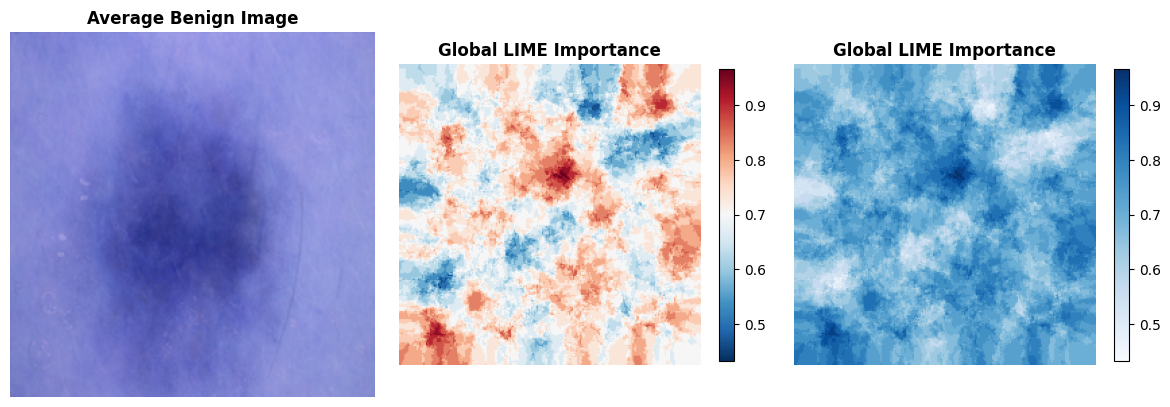

LIME analysis completed for 30 benign images!
Global explanation shows regions that consistently contribute to BENIGN prediction


In [ ]:
import os
import glob
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing import image
from tensorflow.keras.applications.resnet50 import preprocess_input
import matplotlib.pyplot as plt
from lime import lime_image
from skimage.segmentation import mark_boundaries

# Paths
MODEL_PATH = '/content/drive/MyDrive/SOK/resnet50_sk_detection_finetuned.h5'
BENIGN_DIR = '/content/drive/MyDrive/SOK/skin-cancer/train/benign'  # Changed to benign directory

# Load model
model = load_model(MODEL_PATH)

# Load 30 benign images
def load_benign_images():
    X = []
    for path in glob.glob(os.path.join(BENIGN_DIR, "*.*"))[:30]:  # Changed to benign
        img = image.load_img(path, target_size=(224, 224))
        x = preprocess_input(np.expand_dims(image.img_to_array(img), axis=0))
        X.append(x[0])
    return np.array(X)

X_benign = load_benign_images()  # Changed variable name
print(f"Loaded {len(X_benign)} benign images")

# Model wrapper
def model_wrapper(x):
    if len(x.shape) == 3:
        x = np.expand_dims(x, axis=0)

    x_processed = preprocess_input(x.copy())
    preds = model.predict(x_processed, verbose=0)
    prob_malignant = preds.flatten()
    prob_benign = 1 - prob_malignant
    return np.column_stack([prob_benign, prob_malignant])

# Create LIME explainer
explainer = lime_image.LimeImageExplainer()

# Generate LIME explanations for all 30 benign images
lime_explanations = []
importance_maps = []

print("Generating LIME explanations for 30 benign images...")
for i in range(len(X_benign)):
    img_original = ((X_benign[i] + [103.939, 116.779, 123.68])).clip(0, 255).astype(np.uint8)

    explanation = explainer.explain_instance(
        img_original,
        model_wrapper,
        top_labels=2,
        hide_color=0,
        num_samples=100,
        num_features=30
    )

    lime_explanations.append(explanation)

    # Extract importance map for BENIGN class (class 0)
    temp_heat, mask_heat = explanation.get_image_and_mask(
        0,  #
        positive_only=True,
        num_features=30,
        min_weight=0.00001,
        hide_rest=False
    )
    importance_maps.append(mask_heat)

# Create global explanation
print("\nCreating global LIME explanation from 30 benign images...")
global_importance = np.mean(importance_maps, axis=0)

# Visualize global result
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
avg_img = np.mean([((X_benign[i] + [103.939, 116.779, 123.68]) / 255.0).clip(0, 1) for i in range(5)], axis=0)
plt.imshow(avg_img)
plt.title('Average Benign Image', fontsize=12, fontweight='bold')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(global_importance, cmap='RdBu_r')
plt.title('Global LIME Importance', fontsize=12, fontweight='bold')
plt.colorbar(shrink=0.8)
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(global_importance, cmap='Blues')
plt.title('Global LIME Importance', fontsize=12, fontweight='bold')
plt.colorbar(shrink=0.8)
plt.axis('off')

plt.tight_layout()
plt.show()

print(f"LIME analysis completed for {len(X_benign)} benign images!")
print("Global explanation shows regions that consistently contribute to BENIGN prediction")

Loaded 30 malignant images
Generating LIME explanations for 30 malignant images...


  0%|          | 0/100 [00:00<?, ?it/s]

  0%|          | 0/100 [00:00<?, ?it/s]

  0%|          | 0/100 [00:00<?, ?it/s]

  0%|          | 0/100 [00:00<?, ?it/s]

  0%|          | 0/100 [00:00<?, ?it/s]

... (22 outputs left out)

  0%|          | 0/100 [00:00<?, ?it/s]

  0%|          | 0/100 [00:00<?, ?it/s]

  0%|          | 0/100 [00:00<?, ?it/s]


Creating global LIME explanation from 30 malignant images...


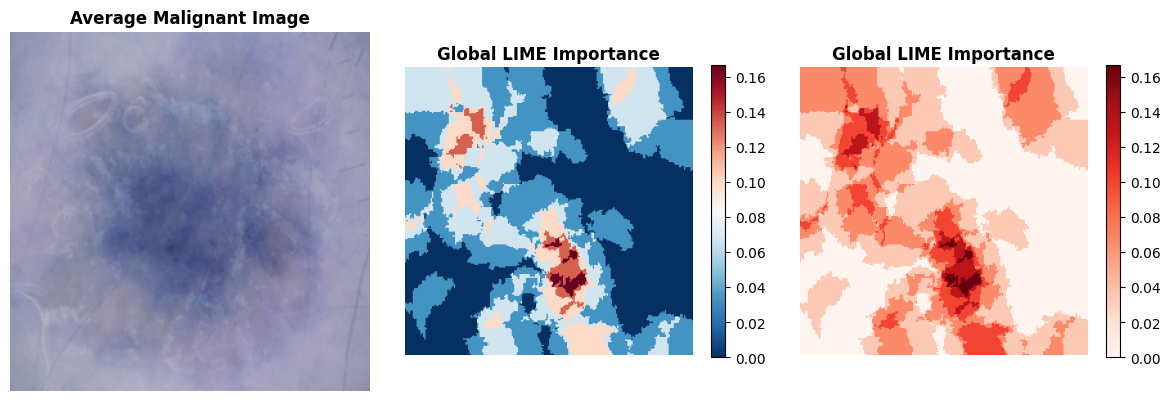

LIME analysis completed for 30 malignant images!
Global explanation shows regions that consistently contribute to MALIGNANT prediction


In [ ]:
import os
import glob
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing import image
from tensorflow.keras.applications.resnet50 import preprocess_input
import matplotlib.pyplot as plt
from lime import lime_image
from skimage.segmentation import mark_boundaries

# Paths
MODEL_PATH = '/content/drive/MyDrive/SOK/resnet50_sk_detection_finetuned.h5'
MALIGNANT_DIR = '/content/drive/MyDrive/SOK/skin-cancer/train/malignant'

# Load model
model = load_model(MODEL_PATH)

# Load 30 malignant images
def load_malignant_images():
    X = []
    for path in glob.glob(os.path.join(MALIGNANT_DIR, "*.*"))[:30]:  # Changed to malignant
        img = image.load_img(path, target_size=(224, 224))
        x = preprocess_input(np.expand_dims(image.img_to_array(img), axis=0))
        X.append(x[0])
    return np.array(X)

X_malignant = load_malignant_images()  # Changed variable name
print(f"Loaded {len(X_malignant)} malignant images")

# Model wrapper
def model_wrapper(x):
    if len(x.shape) == 3:
        x = np.expand_dims(x, axis=0)

    x_processed = preprocess_input(x.copy())
    preds = model.predict(x_processed, verbose=0)
    prob_malignant = preds.flatten()
    prob_benign = 1 - prob_malignant
    return np.column_stack([prob_benign, prob_malignant])


# Create LIME explainer
explainer = lime_image.LimeImageExplainer()

# Generate LIME explanations for all 30 malignant images
lime_explanations = []
importance_maps = []

print("Generating LIME explanations for 30 malignant images...")
for i in range(len(X_malignant)):
    img_original = ((X_malignant[i] + [103.939, 116.779, 123.68])).clip(0, 255).astype(np.uint8)

    explanation = explainer.explain_instance(
        img_original,
        model_wrapper,
        top_labels=2,
        hide_color=0,
        num_samples=100,
        num_features=30
    )

    lime_explanations.append(explanation)


    temp_heat, mask_heat = explanation.get_image_and_mask(
        1,
        positive_only=True,
        num_features=30,
        min_weight=0.00001,
        hide_rest=False
    )
    importance_maps.append(mask_heat)

# Create global explanation
print("\nCreating global LIME explanation from 30 malignant images...")
global_importance = np.mean(importance_maps, axis=0)

# Visualize global result
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
avg_img = np.mean([((X_malignant[i] + [103.939, 116.779, 123.68]) / 255.0).clip(0, 1) for i in range(5)], axis=0)
plt.imshow(avg_img)
plt.title('Average Malignant Image', fontsize=12, fontweight='bold')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(global_importance, cmap='RdBu_r')
plt.title('Global LIME Importance', fontsize=12, fontweight='bold')
plt.colorbar(shrink=0.8)
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(global_importance, cmap='Reds')  # Changed colormap to Reds for malignant
plt.title('Global LIME Importance', fontsize=12, fontweight='bold')
plt.colorbar(shrink=0.8)
plt.axis('off')

plt.tight_layout()
plt.show()

print(f"LIME analysis completed for {len(X_malignant)} malignant images!")
print("Global explanation shows regions that consistently contribute to MALIGNANT prediction")

#GradCAM Global

In [ ]:
import os
import numpy as np
import tensorflow as tf
import cv2
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing import image
import matplotlib.pyplot as plt
import glob

# Paths
model_path = "/content/drive/MyDrive/SOK/model/resnet50_sk_detection_finetuned.h5"
BENIGN_DIR = "/content/drive/MyDrive/SOK/test/benign_test"

# Load model
model = load_model(model_path)
last_conv_layer_name = "conv5_block3_out"

# Modified Grad-CAM function for specific class
def make_gradcam_heatmap(img_array, model, last_conv_layer_name, class_index=0):
    grad_model = tf.keras.models.Model(
        [model.inputs], [model.get_layer(last_conv_layer_name).output, model.output]
    )
    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_array)
        # Use specified class instead of predicted class
        class_channel = predictions[:, class_index]

    grads = tape.gradient(class_channel, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_outputs = conv_outputs[0]

    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)

    heatmap = tf.maximum(heatmap, 0) / tf.math.reduce_max(heatmap)
    return heatmap.numpy()

# Load 30 benign images
def load_benign_images():
    X = []
    image_paths = []
    for path in glob.glob(os.path.join(BENIGN_DIR, "*.*"))[:30]:
        if path.lower().endswith(('.png', '.jpg', '.jpeg')):
            img = image.load_img(path, target_size=(224, 224))
            img_array = image.img_to_array(img)
            img_array = tf.keras.applications.resnet50.preprocess_input(img_array)
            X.append(img_array)
            image_paths.append(path)
    return np.array(X), image_paths

X_benign, benign_paths = load_benign_images()
print(f"Loaded {len(X_benign)} benign images")

# Generate Grad-CAM heatmaps for all benign images
gradcam_heatmaps = []
original_images = []

print("Generating Grad-CAM heatmaps for benign images...")
for i in range(len(X_benign)):
    print(f"Processing benign image {i+1}/{len(X_benign)}...")

    # Prepare image for model
    img_array = np.expand_dims(X_benign[i], axis=0)

    # Generate Grad-CAM for benign class (class 0)
    heatmap = make_gradcam_heatmap(img_array, model, last_conv_layer_name, class_index=0)

    # Resize heatmap to match input image size
    heatmap_resized = cv2.resize(heatmap, (224, 224))
    gradcam_heatmaps.append(heatmap_resized)

    # Store original image for averaging
    original_img = cv2.imread(benign_paths[i])
    original_img = cv2.resize(original_img, (224, 224))
    original_images.append(original_img)

# Create global Grad-CAM explanation
print("\nCreating global Grad-CAM explanation...")
global_gradcam = np.mean(gradcam_heatmaps, axis=0)
avg_original_img = np.mean(original_images, axis=0).astype(np.uint8)

# Visualize global results
plt.figure(figsize=(15, 5))

# Average benign image
plt.subplot(1, 2, 1)
avg_img_rgb = cv2.cvtColor(avg_original_img, cv2.COLOR_BGR2RGB)
plt.imshow(avg_img_rgb)
plt.title('Average Benign Image', fontsize=12, fontweight='bold')
plt.axis('off')

# Global Grad-CAM heatmap
# plt.subplot(1, 3, 2)
# plt.imshow(global_gradcam, cmap='hot')
# plt.title('Global Grad-CAM\n(Benign Prediction)', fontsize=12, fontweight='bold')
# plt.colorbar(shrink=0.8)
# plt.axis('off')

# Global overlay
plt.subplot(1, 2, 2)
heatmap_colored = cv2.applyColorMap(np.uint8(255 * global_gradcam), cv2.COLORMAP_JET)
superimposed_global = cv2.addWeighted(avg_original_img, 0.6, heatmap_colored, 0.4, 0)
plt.imshow(cv2.cvtColor(superimposed_global, cv2.COLOR_BGR2RGB))
plt.title('Global Grad-CAM Overlay\n(Benign)', fontsize=12, fontweight='bold')
plt.axis('off')

plt.tight_layout()
plt.show()

# Show some individual examples
print("\nShowing individual Grad-CAM examples...")
plt.figure(figsize=(20, 8))

for i in range(min(5, len(X_benign))):  # Show first 5 examples
    # Original image
    plt.subplot(2, 5, i+1)
    img_rgb = cv2.cvtColor(original_images[i], cv2.COLOR_BGR2RGB)
    plt.imshow(img_rgb)
    plt.title(f'Benign Image {i+1}', fontsize=12, fontweight='bold')
    plt.axis('off')

    # Individual Grad-CAM overlay
    plt.subplot(2, 5, i+6)
    heatmap_colored = cv2.applyColorMap(np.uint8(255 * gradcam_heatmaps[i]), cv2.COLORMAP_JET)
    superimposed_img = cv2.addWeighted(original_images[i], 0.6, heatmap_colored, 0.4, 0)
    plt.imshow(cv2.cvtColor(superimposed_img, cv2.COLOR_BGR2RGB))
    plt.title(f'Grad-CAM {i+1}', fontsize=12, fontweight='bold')
    plt.axis('off')

plt.tight_layout()
plt.show()

print(f"Global Grad-CAM analysis completed for {len(X_benign)} benign images!")
print("Global explanation shows regions that consistently contribute to BENIGN prediction")

In [ ]:
import os
import numpy as np
import tensorflow as tf
import cv2
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing import image
import matplotlib.pyplot as plt
import glob

# Paths
model_path = "/content/drive/MyDrive/SOK/model/resnet50_sk_detection_finetuned.h5"
BENIGN_DIR = "/content/drive/MyDrive/SOK/test/benign_test"

# Load model
model = load_model(model_path)
last_conv_layer_name = "conv5_block3_out"

# Modified Grad-CAM function for specific class
def make_gradcam_heatmap(img_array, model, last_conv_layer_name, class_index=0):
    grad_model = tf.keras.models.Model(
        [model.inputs], [model.get_layer(last_conv_layer_name).output, model.output]
    )
    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_array)
        # Use specified class instead of predicted class
        class_channel = predictions[:, class_index]

    grads = tape.gradient(class_channel, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_outputs = conv_outputs[0]

    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)

    heatmap = tf.maximum(heatmap, 0) / tf.math.reduce_max(heatmap)
    return heatmap.numpy()

# Load 30 benign images
def load_benign_images():
    X = []
    image_paths = []
    for path in glob.glob(os.path.join(BENIGN_DIR, "*.*"))[:30]:
        if path.lower().endswith(('.png', '.jpg', '.jpeg')):
            img = image.load_img(path, target_size=(224, 224))
            img_array = image.img_to_array(img)
            img_array = tf.keras.applications.resnet50.preprocess_input(img_array)
            X.append(img_array)
            image_paths.append(path)
    return np.array(X), image_paths

X_benign, benign_paths = load_benign_images()
print(f"Loaded {len(X_benign)} benign images")

# Generate Grad-CAM heatmaps for all benign images
gradcam_heatmaps = []
original_images = []

print("Generating Grad-CAM heatmaps for benign images...")
for i in range(len(X_benign)):
    print(f"Processing benign image {i+1}/{len(X_benign)}...")

    # Prepare image for model
    img_array = np.expand_dims(X_benign[i], axis=0)

    # Generate Grad-CAM for benign class (class 0)
    heatmap = make_gradcam_heatmap(img_array, model, last_conv_layer_name, class_index=0)

    # Resize heatmap to match input image size
    heatmap_resized = cv2.resize(heatmap, (224, 224))
    gradcam_heatmaps.append(heatmap_resized)

    # Store original image for averaging
    original_img = cv2.imread(benign_paths[i])
    original_img = cv2.resize(original_img, (224, 224))
    original_images.append(original_img)

# Create global Grad-CAM explanation
print("\nCreating global Grad-CAM explanation...")
global_gradcam = np.mean(gradcam_heatmaps, axis=0)
avg_original_img = np.mean(original_images, axis=0).astype(np.uint8)

# Visualize global results
plt.figure(figsize=(15, 5))

# Average benign image
plt.subplot(1, 2, 1)
avg_img_rgb = cv2.cvtColor(avg_original_img, cv2.COLOR_BGR2RGB)
plt.imshow(avg_img_rgb)
plt.title('Average Benign Image', fontsize=12, fontweight='bold')
plt.axis('off')

# Global overlay
plt.subplot(1, 2, 2)
heatmap_colored = cv2.applyColorMap(np.uint8(255 * global_gradcam), cv2.COLORMAP_JET)
superimposed_global = cv2.addWeighted(avg_original_img, 0.6, heatmap_colored, 0.4, 0)
plt.imshow(cv2.cvtColor(superimposed_global, cv2.COLOR_BGR2RGB))
plt.title('Global Grad-CAM Overlay\n(Benign)', fontsize=12, fontweight='bold')
plt.axis('off')

plt.tight_layout()
plt.show()

# Show some individual examples
print("\nShowing individual Grad-CAM examples...")
plt.figure(figsize=(20, 8))

for i in range(min(5, len(X_benign))):  # Show first 5 examples
    # Original image
    plt.subplot(2, 5, i+1)
    img_rgb = cv2.cvtColor(original_images[i], cv2.COLOR_BGR2RGB)
    plt.imshow(img_rgb)
    plt.title(f'Benign Image {i+1}', fontsize=12, fontweight='bold')
    plt.axis('off')

    # Individual Grad-CAM overlay
    plt.subplot(2, 5, i+6)
    heatmap_colored = cv2.applyColorMap(np.uint8(255 * gradcam_heatmaps[i]), cv2.COLORMAP_JET)
    superimposed_img = cv2.addWeighted(original_images[i], 0.6, heatmap_colored, 0.4, 0)
    plt.imshow(cv2.cvtColor(superimposed_img, cv2.COLOR_BGR2RGB))
    plt.title(f'Grad-CAM {i+1}', fontsize=12, fontweight='bold')
    plt.axis('off')

plt.tight_layout()
plt.show()

print(f"Global Grad-CAM analysis completed for {len(X_benign)} benign images!")
print("Global explanation shows regions that consistently contribute to BENIGN prediction")

In [ ]:
import os
import numpy as np
import tensorflow as tf
import cv2
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing import image
import matplotlib.pyplot as plt
import glob

# Paths
model_path = "/content/drive/MyDrive/SOK/model/resnet50_sk_detection_finetuned.h5"
MALIGNANT_DIR = "/content/drive/MyDrive/SOK/test/malignant"

# Load model
model = load_model(model_path)
last_conv_layer_name = "conv5_block3_out"

# Fixed Grad-CAM function for single output model
def make_gradcam_heatmap(img_array, model, last_conv_layer_name, for_malignant=True):
    grad_model = tf.keras.models.Model(
        [model.inputs], [model.get_layer(last_conv_layer_name).output, model.output]
    )
    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_array)
        # For single output model - predictions shape is (1, 1)
        if for_malignant:
            # Use the sigmoid output directly (higher = more malignant)
            class_channel = predictions[:, 0]
        else:
            # For benign, use 1 - sigmoid output (higher = more benign)
            class_channel = 1 - predictions[:, 0]

    grads = tape.gradient(class_channel, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_outputs = conv_outputs[0]

    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)

    heatmap = tf.maximum(heatmap, 0) / tf.math.reduce_max(heatmap)
    return heatmap.numpy()

# Load malignant images
def load_malignant_images():
    X = []
    image_paths = []
    for path in glob.glob(os.path.join(MALIGNANT_DIR, "*.*"))[:30]:
        if path.lower().endswith(('.png', '.jpg', '.jpeg')):
            img = image.load_img(path, target_size=(224, 224))
            img_array = image.img_to_array(img)
            img_array = tf.keras.applications.resnet50.preprocess_input(img_array)
            X.append(img_array)
            image_paths.append(path)
    return np.array(X), image_paths

X_malignant, malignant_paths = load_malignant_images()
print(f"Loaded {len(X_malignant)} malignant images")

# Test model output to confirm
test_pred = model.predict(np.expand_dims(X_malignant[0], axis=0))
print(f"Model output shape: {test_pred.shape}")
print(f"Sample prediction: {test_pred}")

# Generate Grad-CAM heatmaps for all malignant images
gradcam_heatmaps = []
original_images = []

print("Generating Grad-CAM heatmaps for malignant images...")
for i in range(len(X_malignant)):
    print(f"Processing malignant image {i+1}/{len(X_malignant)}...")

    # Prepare image for model
    img_array = np.expand_dims(X_malignant[i], axis=0)

    # Generate Grad-CAM for malignant prediction
    heatmap = make_gradcam_heatmap(img_array, model, last_conv_layer_name, for_malignant=True)

    # Resize heatmap to match input image size
    heatmap_resized = cv2.resize(heatmap, (224, 224))
    gradcam_heatmaps.append(heatmap_resized)

    # Store original image for averaging
    original_img = cv2.imread(malignant_paths[i])
    original_img = cv2.resize(original_img, (224, 224))
    original_images.append(original_img)

# Create global Grad-CAM explanation
print("\nCreating global Grad-CAM explanation...")
global_gradcam = np.mean(gradcam_heatmaps, axis=0)
avg_original_img = np.mean(original_images, axis=0).astype(np.uint8)

# Visualize global results with professional colormaps
plt.figure(figsize=(15, 5))

# Average malignant image
plt.subplot(1, 2, 1)
avg_img_rgb = cv2.cvtColor(avg_original_img, cv2.COLOR_BGR2RGB)
plt.imshow(avg_img_rgb)
plt.title('Average Malignant Image', fontsize=12, fontweight='bold')
plt.axis('off')

# # Global Grad-CAM heatmap - Professional
# plt.subplot(1, 2, 2)
# plt.imshow(global_gradcam, cmap='Blues')
# plt.title('Global Grad-CAM\n(Malignant Prediction)', fontsize=12, fontweight='bold')
# plt.colorbar(shrink=0.8)
# plt.axis('off')

# Professional overlay
plt.subplot(1, 2, 2)
plt.imshow(avg_img_rgb)
plt.imshow(global_gradcam, cmap='jet', alpha=0.4)
plt.title('Professional Overlay\n(Malignant)', fontsize=12, fontweight='bold')
plt.axis('off')

plt.tight_layout()
plt.show()

# Show individual examples
print("\nShowing individual Grad-CAM examples...")
plt.figure(figsize=(20, 12))

for i in range(min(5, len(X_malignant))):
    # Original image
    plt.subplot(2, 5, i+1)
    img_rgb = cv2.cvtColor(original_images[i], cv2.COLOR_BGR2RGB)
    plt.imshow(img_rgb)
    plt.title(f'Malignant Image {i+1}', fontsize=12, fontweight='bold')
    plt.axis('off')

    # Professional heatmap
    # plt.subplot(3, 5, i+6)
    # plt.imshow(gradcam_heatmaps[i], cmap='Blues')
    # plt.title(f'Grad-CAM Heatmap {i+1}', fontsize=12, fontweight='bold')
    # plt.colorbar(shrink=0.6)
    # plt.axis('off')

    # Professional overlay
    plt.subplot(2, 5, i+11)
    plt.imshow(img_rgb)
    plt.imshow(gradcam_heatmaps[i], cmap='jet', alpha=0.4)
    plt.title(f'Professional Overlay {i+1}', fontsize=12, fontweight='bold')
    plt.axis('off')

plt.tight_layout()
plt.show()

print(f"Global Grad-CAM analysis completed for {len(X_malignant)} malignant images!")
print("Global explanation shows regions that consistently contribute to MALIGNANT prediction")